In [11]:
!pip -q install ultralytics opencv-python-headless \
    huggingface_hub pandas matplotlib tqdm

In [2]:
from google.colab import userdata
from huggingface_hub import login, snapshot_download

token = userdata.get("HF_TOKEN")
login(token=token)

snapshot_download(
    repo_id="vsbgdhdt/ExDark",
    repo_type="dataset",
    local_dir="/content/ExDark",
)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14699 files:   0%|          | 0/14699 [00:00<?, ?it/s]

HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/vsbgdhdt/ExDark/4ae944c13bb07dde8421ec4669cb0eab6a69c649/data%2Ftrain%2Flabels%2F2015_03220_jpg.rf.9f4f217b724952563eac4ca241687078.txt?%2Fdatasets%2Fvsbgdhdt%2FExDark%2Fresolve%2F4ae944c13bb07dde8421ec4669cb0eab6a69c649%2Fdata%2Ftrain%2Flabels%2F2015_03220_jpg.rf.9f4f217b724952563eac4ca241687078.txt=&etag=%2258ab0c1e15fbf4593e4dabfd104812456213085c%22
Rate limited. Waiting 235.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/vsbgdhdt/ExDark/4ae944c13bb07dde8421ec4669cb0eab6a69c649/data%2Ftrain%2Flabels%2F2015_03222_jpg.rf.3660b01ee796134e77f380a8690a68fb.txt?%2Fdatasets%2Fvsbgdhdt%2FExDark%2Fresolve%2F4ae944c13bb07dde8421ec4669cb0eab6a69c649%2Fdata%2Ftrain%2Flabels%2F2015_03222_jpg.rf.3660b01ee796134e77f380a8690a68fb.txt=&etag=%22819ace006ee73180516d6fd5dfaa0a773454ad19%22
Rate limited. Waiting 235.0s before retry [Retry 

'/content/ExDark'

In [18]:
from pathlib import Path

root = Path("/content/ExDark")

for path in [
    root / "data.yaml",
    root / "data" / "train" / "images",
    root / "data" / "train" / "labels",
]:
    print(f"{path}: {'FOUND' if path.exists() else 'NOT FOUND'}")

/content/ExDark/data.yaml: NOT FOUND
/content/ExDark/data/train/images: FOUND
/content/ExDark/data/train/labels: FOUND


In [19]:
!find /content/ExDark -maxdepth 4 -type d | head -60
!find /content/ExDark -name "*.yaml"

/content/ExDark
/content/ExDark/.cache
/content/ExDark/.cache/huggingface
/content/ExDark/.cache/huggingface/trees
/content/ExDark/.cache/huggingface/download
/content/ExDark/.cache/huggingface/download/data
/content/ExDark/data
/content/ExDark/data/valid
/content/ExDark/data/valid/labels
/content/ExDark/data/valid/images
/content/ExDark/data/train
/content/ExDark/data/train/labels
/content/ExDark/data/train/images
/content/ExDark/data/test
/content/ExDark/data/test/labels
/content/ExDark/data/test/images
/content/ExDark/exdark.yaml
/content/ExDark/data/data.yaml
/content/ExDark/data/detectionbench_data.yaml


In [5]:
from pathlib import Path

for yaml_file in [
    Path("/content/ExDark/data/data.yaml"),
    Path("/content/ExDark/data/detectionbench_data.yaml"),
]:
    print(f"\n--- {yaml_file.name} ---")
    print(yaml_file.read_text())


--- data.yaml ---
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 12
names: ['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']

roboflow:
  workspace: my-workspace-ohnbt
  project: exclusively-dark-image
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/my-workspace-ohnbt/exclusively-dark-image/dataset/2

--- detectionbench_data.yaml ---
# detectionbench_data.yaml
# Corrected Ultralytics dataset config for this Roboflow export.
#
# The Roboflow-generated data.yaml in this same directory uses
# `train: ../train/images` etc., which Ultralytics resolves relative to the
# yaml's own directory -- since train/valid/test live *inside* this
# directory (not one level up), that relative path is wrong. This file uses
# an explicit `path:` + non-relative splits instead.

path: data
train: train/images
val: valid/images
test: test/images
nc: 12
names:
  0: Bicycle
  1: Boat
  2: Bottle
  3: Bus
  4: 

In [6]:
from pathlib import Path

root = Path("/content/ExDark/data")

for split in ["train", "valid", "test"]:
    images = list((root / split / "images").glob("*"))
    labels = list((root / split / "labels").glob("*.txt"))

    print(
        f"{split:5} | Images: {len(images):5} | "
        f"Label files: {len(labels):5}"
    )

train | Images:  5875 | Label files:  5874
valid | Images:   737 | Label files:   736
test  | Images:   735 | Label files:   734


In [7]:
!pip -q install ultralytics

In [8]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("/content/ExDark/data/data.yaml")

print("Dataset YAML:", data)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Dataset YAML: {'train': '/content/ExDark/data/train/images', 'val': '/content/ExDark/data/valid/images', 'test': '/content/ExDark/data/test/images', 'nc': 12, 'names': {0: 'Bicycle', 1: 'Boat', 2: 'Bottle', 3: 'Bus', 4: 'Car', 5: 'Cat', 6: 'Chair', 7: 'Cup', 8: 'Dog', 9: 'Motorbike', 10: 'People', 11: 'Table'}, 'roboflow': {'workspace': 'my-workspace-ohnbt', 'project': 'exclusively-dark-image', 'version': 2, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/my-workspace-ohnbt/exclusively-dark-image/dataset/2'}, 'yaml_file': '/content/ExDark/data/data.yaml', 'channels': 3, 'path': PosixPath('/content/ExDark/data')}


In [17]:
from pathlib import Path
import yaml

data_dir = Path("/content/ExDark/data")
yaml_path = Path("/content/ExDark/exdark.yaml")

config = {
    "path": str(data_dir),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 12,
    "names": [
        "Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
        "Chair", "Cup", "Dog", "Motorbike", "People", "Table"
    ],
}

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(yaml_path.read_text())

path: /content/ExDark/data
train: train/images
val: valid/images
test: test/images
nc: 12
names:
- Bicycle
- Boat
- Bottle
- Bus
- Car
- Cat
- Chair
- Cup
- Dog
- Motorbike
- People
- Table



In [15]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("/content/ExDark/exdark.yaml")

print("Train:", data["train"])
print("Validation:", data["val"])
print("Test:", data["test"])
print("Classes:", data["names"])

Train: /content/ExDark/data/train/images
Validation: /content/ExDark/data/valid/images
Test: /content/ExDark/data/test/images
Classes: {0: 'Bicycle', 1: 'Boat', 2: 'Bottle', 3: 'Bus', 4: 'Car', 5: 'Cat', 6: 'Chair', 7: 'Cup', 8: 'Dog', 9: 'Motorbike', 10: 'People', 11: 'Table'}


In [20]:
from pathlib import Path
import yaml

data_dir = Path("/content/ExDark/data")
yaml_path = Path("/content/ExDark/exdark.yaml")

config = {
    "path": str(data_dir),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 12,
    "names": [
        "Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
        "Chair", "Cup", "Dog", "Motorbike", "People", "Table"
    ],
}

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(yaml_path.read_text())

path: /content/ExDark/data
train: train/images
val: valid/images
test: test/images
nc: 12
names:
- Bicycle
- Boat
- Bottle
- Bus
- Car
- Cat
- Chair
- Cup
- Dog
- Motorbike
- People
- Table



In [21]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("/content/ExDark/exdark.yaml")

print("Train:", data["train"])
print("Validation:", data["val"])
print("Test:", data["test"])
print("Classes:", data["names"])

Train: /content/ExDark/data/train/images
Validation: /content/ExDark/data/valid/images
Test: /content/ExDark/data/test/images
Classes: {0: 'Bicycle', 1: 'Boat', 2: 'Bottle', 3: 'Bus', 4: 'Car', 5: 'Cat', 6: 'Chair', 7: 'Cup', 8: 'Dog', 9: 'Motorbike', 10: 'People', 11: 'Table'}


In [22]:
from pathlib import Path

root = Path("/content/ExDark/data")

for split in ["train", "valid", "test"]:
    image_dir = root / split / "images"
    label_dir = root / split / "labels"

    image_stems = {p.stem for p in image_dir.iterdir() if p.is_file()}
    label_stems = {p.stem for p in label_dir.glob("*.txt")}

    print(f"\n{split}:")
    print("Images without matching labels:", sorted(image_stems - label_stems)[:10])
    print("Labels without matching images:", sorted(label_stems - image_stems)[:10])


train:
Images without matching labels: ['metadata']
Labels without matching images: []

valid:
Images without matching labels: ['metadata']
Labels without matching images: []

test:
Images without matching labels: ['metadata']
Labels without matching images: []


In [23]:
from pathlib import Path

root = Path("/content/ExDark/data")
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "valid", "test"]:
    image_dir = root / split / "images"
    label_dir = root / split / "labels"

    images = [
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in image_exts
    ]
    labels = list(label_dir.rglob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(image_stems - label_stems))
    print("Labels without images:", len(label_stems - image_stems))


TRAIN
Images: 5874
Labels: 5874
Images without labels: 0
Labels without images: 0

VALID
Images: 736
Labels: 736
Images without labels: 0
Labels without images: 0

TEST
Images: 734
Labels: 734
Images without labels: 0
Labels without images: 0


In [24]:
!pip -q install ultralytics

from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.val(
    data="/content/ExDark/exdark.yaml",
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
)

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 949.5±415.7 MB/s, size: 32.3 KB)
val: Scanning /content/ExDark/data/valid/labels... 736 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 736/736 1.8Kit/s 0.4s
val: New cache created: /content/ExDark/data/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 46/46 5.0it/s 9.1s
                   all        736       2282     0.0128     0.0505    0.00159   0.000864
                person         74        117      0.001      0.222   0.000718   0.000157
               bicycle         65        139    0.00169     0.0576   0.000157   7.55e-05
                   car         65        146   0.000488     0.0411   2.28e-05   9.66e-06
            motorcycle         45         55          0          0         

In [26]:
!pip -q install -U ultralytics pandas matplotlib pyyaml

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


In [27]:
from pathlib import Path
import yaml
import json
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from ultralytics import YOLO
from PIL import Image

# Dataset paths
DATA_ROOT = Path("/content/ExDark/data")
TEST_IMAGES = DATA_ROOT / "test" / "images"
TEST_LABELS = DATA_ROOT / "test" / "labels"
OUTPUT_DIR = Path("/content/exdark_baseline")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the custom YAML we created earlier
DATA_YAML = Path("/content/ExDark/exdark.yaml")

assert TEST_IMAGES.exists(), f"Missing: {TEST_IMAGES}"
assert TEST_LABELS.exists(), f"Missing: {TEST_LABELS}"
assert DATA_YAML.exists(), f"Missing: {DATA_YAML}"

with open(DATA_YAML) as f:
    config = yaml.safe_load(f)

EXDARK_NAMES = config["names"]
if isinstance(EXDARK_NAMES, dict):
    EXDARK_NAMES = {
        int(k): v for k, v in EXDARK_NAMES.items()
    }
else:
    EXDARK_NAMES = dict(enumerate(EXDARK_NAMES))

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

test_images = sorted(
    p for p in TEST_IMAGES.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

print("Test images:", len(test_images))
print("ExDark classes:", EXDARK_NAMES)
print("Output directory:", OUTPUT_DIR)

Test images: 734
ExDark classes: {0: 'Bicycle', 1: 'Boat', 2: 'Bottle', 3: 'Bus', 4: 'Car', 5: 'Cat', 6: 'Chair', 7: 'Cup', 8: 'Dog', 9: 'Motorbike', 10: 'People', 11: 'Table'}
Output directory: /content/exdark_baseline


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [28]:
MODEL_NAME = "yolov8n.pt"

model = YOLO(MODEL_NAME)

print("Model loaded:", MODEL_NAME)
print("Number of pretrained classes:", len(model.names))
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

print("\nPretrained class names:")
print(model.names)

Model loaded: yolov8n.pt
Number of pretrained classes: 80
Device: GPU

Pretrained class names:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 6

In [29]:
# ExDark class name -> COCO class name
CATEGORY_MAPPING = {
    "Bicycle": "bicycle",
    "Boat": "boat",
    "Bottle": "bottle",
    "Bus": "bus",
    "Car": "car",
    "Cat": "cat",
    "Chair": "chair",
    "Dog": "dog",
    "Motorbike": "motorcycle",
    "People": "person",
}

# Build a mapping from COCO class IDs to ExDark class IDs
COCO_TO_EXDARK = {}

for exdark_id, exdark_name in EXDARK_NAMES.items():
    coco_name = CATEGORY_MAPPING.get(exdark_name)

    if coco_name is None:
        continue

    matching_ids = [
        int(class_id)
        for class_id, name in model.names.items()
        if name.lower() == coco_name.lower()
    ]

    if len(matching_ids) != 1:
        raise ValueError(
            f"Could not uniquely map {coco_name}: {matching_ids}"
        )

    COCO_TO_EXDARK[matching_ids[0]] = exdark_id

EVALUATED_CLASSES = sorted(set(COCO_TO_EXDARK.values()))

print("COCO -> ExDark:", COCO_TO_EXDARK)
print("\nEvaluated categories:")

for class_id in EVALUATED_CLASSES:
    print(f"{class_id}: {EXDARK_NAMES[class_id]}")

print("\nExcluded from primary metrics: Cup, Table")

COCO -> ExDark: {1: 0, 8: 1, 39: 2, 5: 3, 2: 4, 15: 5, 56: 6, 16: 8, 3: 9, 0: 10}

Evaluated categories:
0: Bicycle
1: Boat
2: Bottle
3: Bus
4: Car
5: Cat
6: Chair
8: Dog
9: Motorbike
10: People

Excluded from primary metrics: Cup, Table


In [31]:
IMG_SIZE = 640
BATCH_SIZE = 16
CONF_THRESHOLD = 0.001
NMS_IOU_THRESHOLD = 0.7
MAX_DETECTIONS = 300

DEVICE = 0 if torch.cuda.is_available() else "cpu"

predictions = {}
inference_times = []

start_total = time.perf_counter()

results = model.predict(
    source=[str(p) for p in test_images],
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    conf=CONF_THRESHOLD,
    iou=NMS_IOU_THRESHOLD,
    max_det=MAX_DETECTIONS,
    device=DEVICE,
    stream=True,
    verbose=False,
)

for i, result in enumerate(results, start=1):
    image_path = Path(result.path)
    image_key = image_path.name

    boxes = result.boxes

    if boxes is None or len(boxes) == 0:
        predictions[image_key] = []
    else:
        xyxy = boxes.xyxy.cpu().numpy()
        confs = boxes.conf.cpu().numpy()
        classes = boxes.cls.cpu().numpy().astype(int)

        detections = []

        for box, conf, coco_id in zip(xyxy, confs, classes):
            if coco_id not in COCO_TO_EXDARK:
                continue

            detections.append({
                "class_id": COCO_TO_EXDARK[coco_id],
                "confidence": float(conf),
                "bbox": box.astype(float).tolist(),
            })

        predictions[image_key] = detections

    inference_times.append(result.speed.get("inference", 0.0))

    if i % 100 == 0 or i == len(test_images):
        print(f"Processed {i}/{len(test_images)} images")

total_seconds = time.perf_counter() - start_total

print("\nInference finished.")
print("Images processed:", len(predictions))
print("Elapsed time (including overhead):", round(total_seconds, 2), "seconds")
print("Average YOLO inference time:", round(np.mean(inference_times), 2), "ms/image")
print(
    "Mapped detections:",
    sum(len(d) for d in predictions.values())
)

OutOfMemoryError: CUDA out of memory. Tried to allocate 3.36 GiB. GPU 0 has a total capacity of 14.56 GiB of which 987.81 MiB is free. Including non-PyTorch memory, this process has 13.60 GiB memory in use. Of the allocated memory 13.17 GiB is allocated by PyTorch, and 309.34 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [32]:
import gc
import torch

# Release the failed prediction generator and cached tensors
if "results" in globals():
    del results

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(torch.cuda.memory_summary() if False else
          f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Allocated: 0.85 GB


In [33]:
from pathlib import Path
import time
import json
import gc
import numpy as np
import torch

# Configuration
IMG_SIZE = 640
BATCH_SIZE = 4              # Much smaller than the original batch of 16
CONF_THRESHOLD = 0.001
NMS_IOU_THRESHOLD = 0.7
MAX_DETECTIONS = 300

DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Ensure output directory exists
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Store predictions and timing results
predictions = {}
inference_times = []

# Process only a small group of images at a time
CHUNK_SIZE = 4
total_images = len(test_images)
start_total = time.perf_counter()

for start in range(0, total_images, CHUNK_SIZE):
    batch_paths = test_images[start:start + CHUNK_SIZE]

    batch_results = model.predict(
        source=[str(p) for p in batch_paths],
        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        conf=CONF_THRESHOLD,
        iou=NMS_IOU_THRESHOLD,
        max_det=MAX_DETECTIONS,
        device=DEVICE,
        stream=False,
        verbose=False,
    )

    for result in batch_results:
        image_key = Path(result.path).name
        boxes = result.boxes

        detections = []

        if boxes is not None and len(boxes) > 0:
            xyxy = boxes.xyxy.cpu().numpy()
            confs = boxes.conf.cpu().numpy()
            classes = boxes.cls.cpu().numpy().astype(int)

            for box, conf, coco_id in zip(xyxy, confs, classes):
                if coco_id not in COCO_TO_EXDARK:
                    continue

                detections.append({
                    "class_id": int(COCO_TO_EXDARK[coco_id]),
                    "confidence": float(conf),
                    "bbox": box.astype(float).tolist(),
                })

        predictions[image_key] = detections

        inference_times.append(
            float(result.speed.get("inference", 0.0))
        )

    # Save a checkpoint after each chunk, so progress is recoverable
    with open(OUTPUT_DIR / "baseline_predictions.json", "w") as f:
        json.dump(predictions, f)

    processed = min(start + CHUNK_SIZE, total_images)

    if processed % 100 < CHUNK_SIZE or processed == total_images:
        print(f"Processed {processed}/{total_images} images")

    del batch_results

    # Clear cached memory periodically
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

total_seconds = time.perf_counter() - start_total

print("\nInference completed!")
print("Images processed:", len(predictions))
print("Mapped detections:", sum(len(v) for v in predictions.values()))
print("Elapsed time:", round(total_seconds, 2), "seconds")
print(
    "Mean YOLO inference time:",
    round(float(np.mean(inference_times)), 2),
    "ms/image"
)

print("Predictions saved to:", OUTPUT_DIR / "baseline_predictions.json")

Processed 100/734 images
Processed 200/734 images
Processed 300/734 images
Processed 400/734 images
Processed 500/734 images
Processed 600/734 images
Processed 700/734 images
Processed 734/734 images

Inference completed!
Images processed: 734
Mapped detections: 66548
Elapsed time: 88.44 seconds
Mean YOLO inference time: 10.17 ms/image
Predictions saved to: /content/exdark_baseline/baseline_predictions.json


In [34]:
def load_ground_truth(image_path):
    """
    Load ground-truth boxes for one image.

    Returns a list of dictionaries containing:
    class_id and bbox [x1, y1, x2, y2].
    """
    label_path = TEST_LABELS / f"{image_path.stem}.txt"

    if not label_path.exists():
        return []

    with Image.open(image_path) as im:
        width, height = im.size

    ground_truth = []

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])

            # Evaluate only categories with a defined COCO counterpart
            if class_id not in EVALUATED_CLASSES:
                continue

            xc, yc, bw, bh = map(float, parts[1:])

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            ground_truth.append({
                "class_id": class_id,
                "bbox": [x1, y1, x2, y2],
            })

    return ground_truth


ground_truths = {
    image_path.name: load_ground_truth(image_path)
    for image_path in test_images
}

gt_count = sum(len(items) for items in ground_truths.values())

print("Images with loaded annotations:", len(ground_truths))
print("Ground-truth objects in evaluated classes:", gt_count)

print("\nGround-truth instances per evaluated class:")

for class_id in EVALUATED_CLASSES:
    count = sum(
        1 for items in ground_truths.values()
        for item in items
        if item["class_id"] == class_id
    )
    print(f"{EXDARK_NAMES[class_id]:12}: {count}")

Images with loaded annotations: 734
Ground-truth objects in evaluated classes: 2094

Ground-truth instances per evaluated class:
Bicycle     : 139
Boat        : 93
Bottle      : 136
Bus         : 67
Car         : 282
Cat         : 78
Chair       : 229
Dog         : 90
Motorbike   : 112
People      : 868


In [35]:
from collections import defaultdict

def box_iou(box, boxes):
    """IoU between one xyxy box and an array of xyxy boxes."""
    boxes = np.asarray(boxes, dtype=float)

    if len(boxes) == 0:
        return np.array([])

    x1 = np.maximum(box[0], boxes[:, 0])
    y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2])
    y2 = np.minimum(box[3], boxes[:, 3])

    intersection = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)

    area_a = max(0, box[2] - box[0]) * max(0, box[3] - box[1])
    area_b = (
        np.maximum(0, boxes[:, 2] - boxes[:, 0]) *
        np.maximum(0, boxes[:, 3] - boxes[:, 1])
    )

    union = area_a + area_b - intersection
    return intersection / np.maximum(union, 1e-12)


def compute_ap(recall, precision):
    """101-point interpolated average precision."""
    recall_points = np.linspace(0, 1, 101)

    interpolated = []
    for r in recall_points:
        eligible = precision[recall >= r]
        interpolated.append(eligible.max() if len(eligible) else 0.0)

    return float(np.mean(interpolated))


def evaluate_class(class_id, iou_threshold, confidence_threshold=None):
    """
    Evaluate one class across the full test set.

    AP uses ranked detections. Precision and recall can optionally
    be calculated at a fixed confidence threshold.
    """
    gt_by_image = {}
    total_gt = 0

    for image_name, items in ground_truths.items():
        boxes = [
            item["bbox"] for item in items
            if item["class_id"] == class_id
        ]
        gt_by_image[image_name] = boxes
        total_gt += len(boxes)

    if total_gt == 0:
        return {
            "ap": float("nan"),
            "precision": float("nan"),
            "recall": float("nan"),
            "gt": 0,
            "tp": 0,
            "fp": 0,
        }

    detections = []

    for image_name, items in predictions.items():
        for item in items:
            if item["class_id"] != class_id:
                continue

            if (
                confidence_threshold is not None
                and item["confidence"] < confidence_threshold
            ):
                continue

            detections.append({
                "image": image_name,
                "confidence": item["confidence"],
                "bbox": item["bbox"],
            })

    detections.sort(key=lambda d: d["confidence"], reverse=True)

    matched = {
        image_name: np.zeros(len(boxes), dtype=bool)
        for image_name, boxes in gt_by_image.items()
    }

    tp_flags = []
    fp_flags = []

    for detection in detections:
        image_name = detection["image"]
        gt_boxes = gt_by_image[image_name]

        if not gt_boxes:
            tp_flags.append(0)
            fp_flags.append(1)
            continue

        overlaps = box_iou(detection["bbox"], gt_boxes)
        best_idx = int(np.argmax(overlaps))

        if (
            overlaps[best_idx] >= iou_threshold
            and not matched[image_name][best_idx]
        ):
            matched[image_name][best_idx] = True
            tp_flags.append(1)
            fp_flags.append(0)
        else:
            tp_flags.append(0)
            fp_flags.append(1)

    tp_cumulative = np.cumsum(tp_flags)
    fp_cumulative = np.cumsum(fp_flags)

    if len(tp_flags):
        recall_curve = tp_cumulative / total_gt
        precision_curve = tp_cumulative / np.maximum(
            tp_cumulative + fp_cumulative, 1e-12
        )
        ap = compute_ap(recall_curve, precision_curve)
    else:
        ap = 0.0

    # Fixed-confidence metrics
    if confidence_threshold is not None:
        tp = int(sum(tp_flags))
        fp = int(sum(fp_flags))
        fn = total_gt - tp

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
    else:
        tp = fp = 0
        precision = recall = float("nan")

    return {
        "ap": ap,
        "precision": precision,
        "recall": recall,
        "gt": total_gt,
        "tp": tp,
        "fp": fp,
    }


IOU_THRESHOLDS = np.arange(0.50, 0.96, 0.05)
METRIC_CONFIDENCE = 0.25

rows = []

for class_id in EVALUATED_CLASSES:
    class_aps = []

    for threshold in IOU_THRESHOLDS:
        metrics = evaluate_class(class_id, threshold)
        class_aps.append(metrics["ap"])

    metrics_50 = evaluate_class(
        class_id, 0.50, confidence_threshold=METRIC_CONFIDENCE
    )

    rows.append({
        "class_id": class_id,
        "class_name": EXDARK_NAMES[class_id],
        "ground_truths": metrics_50["gt"],
        "AP50": class_aps[0],
        "AP50_95": float(np.mean(class_aps)),
        "precision@0.25": metrics_50["precision"],
        "recall@0.25": metrics_50["recall"],
    })

class_results = pd.DataFrame(rows)

summary = {
    "model": MODEL_NAME,
    "split": "test",
    "images": len(test_images),
    "evaluated_classes": len(EVALUATED_CLASSES),
    "excluded_classes": ["Cup", "Table"],
    "imgsz": IMG_SIZE,
    "nms_iou": NMS_IOU_THRESHOLD,
    "ap_conf_threshold": CONF_THRESHOLD,
    "fixed_metric_confidence": METRIC_CONFIDENCE,
    "mAP50": float(class_results["AP50"].mean()),
    "mAP50_95": float(class_results["AP50_95"].mean()),
    "mean_precision_at_025": float(class_results["precision@0.25"].mean()),
    "mean_recall_at_025": float(class_results["recall@0.25"].mean()),
    "mean_yolo_inference_ms_per_image": float(np.mean(inference_times)),
    "wall_time_seconds": float(total_seconds),
}

print("\nOVERALL RESULTS")
for key, value in summary.items():
    print(f"{key}: {value}")

print("\nPER-CLASS RESULTS")
display(class_results.round(4))


OVERALL RESULTS
model: yolov8n.pt
split: test
images: 734
evaluated_classes: 10
excluded_classes: ['Cup', 'Table']
imgsz: 640
nms_iou: 0.7
ap_conf_threshold: 0.001
fixed_metric_confidence: 0.25
mAP50: 0.4812512181735168
mAP50_95: 0.25895439611130294
mean_precision_at_025: 0.6574813208609072
mean_recall_at_025: 0.43796016020712364
mean_yolo_inference_ms_per_image: 10.167015117162014
wall_time_seconds: 88.44499608700062

PER-CLASS RESULTS


,class_id,class_name,ground_truths,AP50,AP50_95,precision@0.25,recall@0.25
0,0,Bicycle,139,0.5019,0.2542,0.5303,0.5036
1,1,Boat,93,0.3327,0.1278,0.5417,0.2796
2,2,Bottle,136,0.3807,0.1708,0.5495,0.3676
3,3,Bus,67,0.7087,0.4809,0.7679,0.6418
4,4,Car,282,0.5410,0.2811,0.7444,0.4752
5,5,Cat,78,0.4723,0.2740,0.7391,0.4359
6,6,Chair,229,0.4072,0.2085,0.5862,0.3712
7,8,Dog,90,0.4114,0.2208,0.7333,0.3667
8,9,Motorbike,112,0.4604,0.2640,0.6912,0.4196
9,10,People,868,0.5962,0.3075,0.6912,0.5184


In [36]:
class_results.to_csv(
    OUTPUT_DIR / "baseline_per_class.csv",
    index=False,
)

with open(OUTPUT_DIR / "baseline_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

# Save raw predictions so we don't need to run the baseline again
with open(OUTPUT_DIR / "baseline_predictions.json", "w") as f:
    json.dump(predictions, f)

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, f"({path.stat().st_size / 1024:.1f} KB)")

Saved files:
baseline_per_class.csv (0.9 KB)
baseline_predictions.json (9077.7 KB)
baseline_summary.json (0.5 KB)


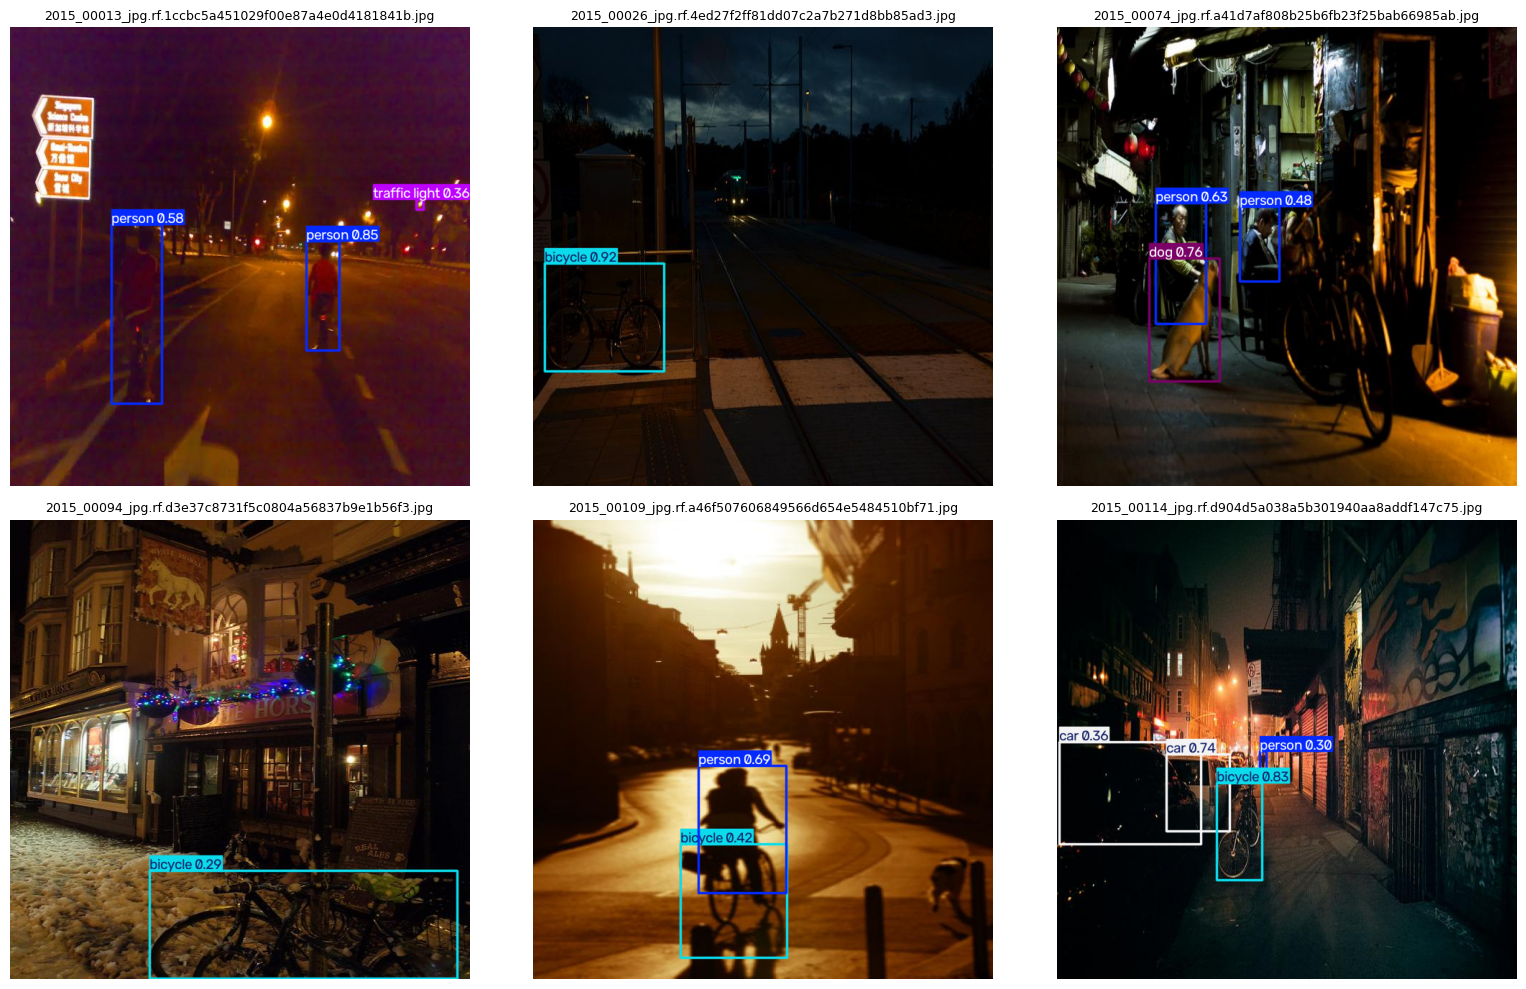

Annotated images saved to: /content/exdark_baseline/visualizations


In [37]:
VIS_DIR = OUTPUT_DIR / "visualizations"
VIS_DIR.mkdir(exist_ok=True)

sample_paths = test_images[:6]

visual_results = model.predict(
    source=[str(p) for p in sample_paths],
    imgsz=IMG_SIZE,
    conf=0.25,
    iou=NMS_IOU_THRESHOLD,
    max_det=MAX_DETECTIONS,
    device=DEVICE,
    verbose=False,
)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for ax, result in zip(axes, visual_results):
    annotated_bgr = result.plot()
    annotated_rgb = annotated_bgr[:, :, ::-1]

    ax.imshow(annotated_rgb)
    ax.set_title(Path(result.path).name, fontsize=9)
    ax.axis("off")

    result.save(filename=str(VIS_DIR / Path(result.path).name))

plt.tight_layout()
plt.show()

print("Annotated images saved to:", VIS_DIR)

In [38]:
import shutil

archive_path = shutil.make_archive(
    "/content/exdark_baseline",
    "zip",
    root_dir=OUTPUT_DIR,
)

print("Archive created:", archive_path)

Archive created: /content/exdark_baseline.zip


In [39]:
from google.colab import files
files.download("/content/exdark_baseline.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
import cv2
import numpy as np
import pandas as pd
import json
import time
import gc
import torch

from pathlib import Path
from ultralytics import YOLO

DATA_ROOT = Path("/content/ExDark/data")
TEST_IMAGES = DATA_ROOT / "test/images"

OUTPUT_ROOT = Path("/content/exdark_phase2")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Confirm that the Phase 1 objects still exist.
required = [
    "model",
    "test_images",
    "COCO_TO_EXDARK",
    "EVALUATED_CLASSES",
    "ground_truths",
    "evaluate_class",
    "EXDARK_NAMES",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        f"Missing Phase 1 variables: {missing}. "
        "Rerun the necessary setup/evaluation cells first."
    )

print("YOLO model:", model.ckpt_path if hasattr(model, "ckpt_path") else "loaded")
print("Test images:", len(test_images))
print("Output directory:", OUTPUT_ROOT)
print("GPU available:", torch.cuda.is_available())

YOLO model: yolov8n.pt
Test images: 734
Output directory: /content/exdark_phase2
GPU available: True


In [41]:
import cv2

GAMMA = 1.5
CLAHE_CLIP_LIMIT = 2.0
CLAHE_TILE_GRID = (8, 8)

GAMMA_DIR = OUTPUT_ROOT / "gamma" / "images"
CLAHE_DIR = OUTPUT_ROOT / "clahe" / "images"

GAMMA_DIR.mkdir(parents=True, exist_ok=True)
CLAHE_DIR.mkdir(parents=True, exist_ok=True)

# Gamma lookup table: gamma > 1 brightens the image
gamma_table = np.array([
    ((i / 255.0) ** (1.0 / GAMMA)) * 255
    for i in range(256)
]).clip(0, 255).astype(np.uint8)

clahe_operator = cv2.createCLAHE(
    clipLimit=CLAHE_CLIP_LIMIT,
    tileGridSize=CLAHE_TILE_GRID
)

def apply_gamma(image):
    return cv2.LUT(image, gamma_table)

def apply_clahe(image):
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    luminance, a, b = cv2.split(lab)

    enhanced_luminance = clahe_operator.apply(luminance)

    enhanced_lab = cv2.merge([enhanced_luminance, a, b])
    return cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)

for i, image_path in enumerate(test_images, start=1):
    image = cv2.imread(str(image_path))

    if image is None:
        print("Warning: could not read", image_path)
        continue

    gamma_image = apply_gamma(image)
    clahe_image = apply_clahe(image)

    if not cv2.imwrite(
        str(GAMMA_DIR / image_path.name), gamma_image
    ):
        raise RuntimeError(f"Failed to save Gamma image: {image_path.name}")

    if not cv2.imwrite(
        str(CLAHE_DIR / image_path.name), clahe_image
    ):
        raise RuntimeError(f"Failed to save CLAHE image: {image_path.name}")

    if i % 100 == 0 or i == len(test_images):
        print(f"Enhanced {i}/{len(test_images)} images")

print("Gamma images:", len(list(GAMMA_DIR.iterdir())))
print("CLAHE images:", len(list(CLAHE_DIR.iterdir())))

Enhanced 100/734 images
Enhanced 200/734 images
Enhanced 300/734 images
Enhanced 400/734 images
Enhanced 500/734 images
Enhanced 600/734 images
Enhanced 700/734 images
Enhanced 734/734 images
Gamma images: 734
CLAHE images: 734


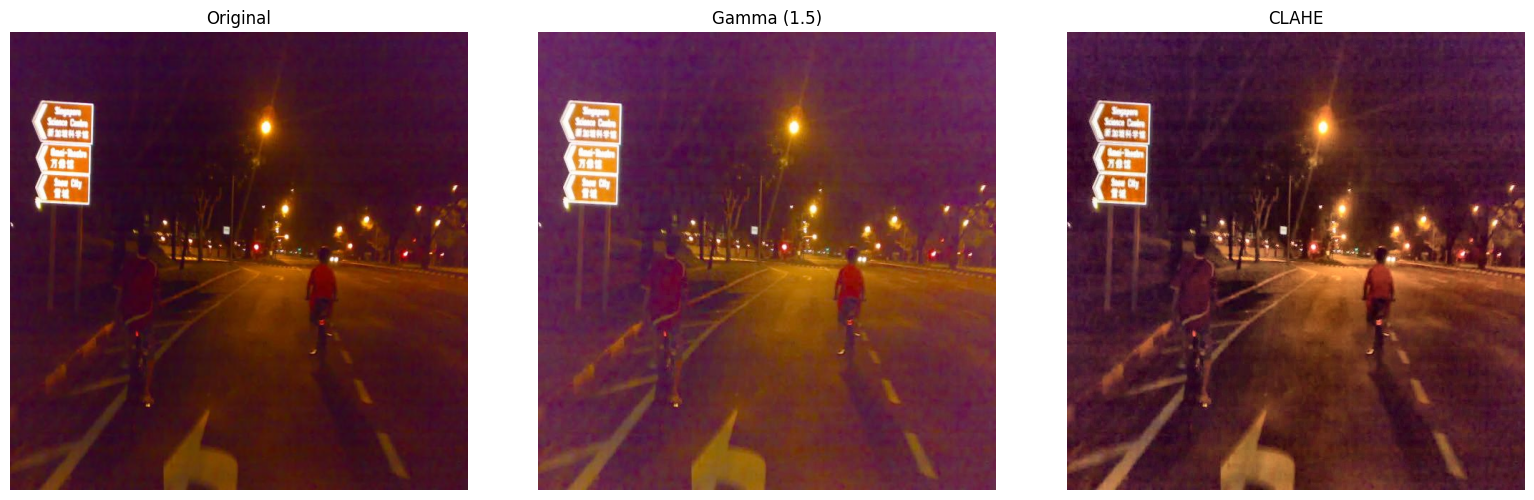

In [42]:
import matplotlib.pyplot as plt

sample_path = test_images[0]

original = cv2.imread(str(sample_path))
gamma_img = cv2.imread(str(GAMMA_DIR / sample_path.name))
clahe_img = cv2.imread(str(CLAHE_DIR / sample_path.name))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, img, title in zip(
    axes,
    [original, gamma_img, clahe_img],
    ["Original", "Gamma (1.5)", "CLAHE"]
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [43]:
IMG_SIZE = 640
CONF_THRESHOLD = 0.001
NMS_IOU_THRESHOLD = 0.7
MAX_DETECTIONS = 300
CHUNK_SIZE = 4

DEVICE = 0 if torch.cuda.is_available() else "cpu"

def run_detection(image_paths, save_path):
    """Run pretrained YOLO on images in small chunks and save predictions."""
    all_predictions = {}
    timings = []
    start_time = time.perf_counter()

    for start in range(0, len(image_paths), CHUNK_SIZE):
        batch_paths = image_paths[start:start + CHUNK_SIZE]

        results = model.predict(
            source=[str(p) for p in batch_paths],
            imgsz=IMG_SIZE,
            conf=CONF_THRESHOLD,
            iou=NMS_IOU_THRESHOLD,
            max_det=MAX_DETECTIONS,
            device=DEVICE,
            stream=False,
            verbose=False,
        )

        for result in results:
            detections = []
            boxes = result.boxes

            if boxes is not None and len(boxes):
                xyxy = boxes.xyxy.cpu().numpy()
                confs = boxes.conf.cpu().numpy()
                classes = boxes.cls.cpu().numpy().astype(int)

                for box, conf, coco_id in zip(xyxy, confs, classes):
                    if int(coco_id) not in COCO_TO_EXDARK:
                        continue

                    detections.append({
                        "class_id": int(COCO_TO_EXDARK[int(coco_id)]),
                        "confidence": float(conf),
                        "bbox": box.astype(float).tolist(),
                    })

            all_predictions[Path(result.path).name] = detections
            timings.append(float(result.speed.get("inference", 0.0)))

        del results
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        processed = min(start + CHUNK_SIZE, len(image_paths))
        if processed % 100 < CHUNK_SIZE or processed == len(image_paths):
            print(f"Processed {processed}/{len(image_paths)}")

    elapsed = time.perf_counter() - start_time

    with open(save_path, "w") as f:
        json.dump(all_predictions, f)

    return all_predictions, {
        "elapsed_seconds": elapsed,
        "mean_inference_ms": float(np.mean(timings)) if timings else 0.0,
    }


def evaluate_predictions(preds):
    """
    Evaluate predictions using the Phase 1 evaluator.
    Requires evaluate_class() and ground_truths from Phase 1.
    """
    global predictions
    predictions = preds

    rows = []
    for class_id in EVALUATED_CLASSES:
        ap_values = [
            evaluate_class(class_id, threshold)["ap"]
            for threshold in np.arange(0.50, 0.96, 0.05)
        ]

        at_50 = evaluate_class(
            class_id, 0.50, confidence_threshold=0.25
        )

        rows.append({
            "class_id": class_id,
            "class_name": EXDARK_NAMES[class_id],
            "ground_truths": at_50["gt"],
            "AP50": ap_values[0],
            "AP50_95": float(np.mean(ap_values)),
            "precision@0.25": at_50["precision"],
            "recall@0.25": at_50["recall"],
        })

    df = pd.DataFrame(rows)

    summary = {
        "mAP50": float(df["AP50"].mean()),
        "mAP50_95": float(df["AP50_95"].mean()),
        "mean_precision@0.25": float(df["precision@0.25"].mean()),
        "mean_recall@0.25": float(df["recall@0.25"].mean()),
    }

    return df, summary

In [44]:
gamma_paths = sorted(
    p for p in GAMMA_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

clahe_paths = sorted(
    p for p in CLAHE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

gamma_preds, gamma_timing = run_detection(
    gamma_paths,
    OUTPUT_ROOT / "gamma_predictions.json"
)

gamma_per_class, gamma_metrics = evaluate_predictions(gamma_preds)

clahe_preds, clahe_timing = run_detection(
    clahe_paths,
    OUTPUT_ROOT / "clahe_predictions.json"
)

clahe_per_class, clahe_metrics = evaluate_predictions(clahe_preds)

print("Gamma:", gamma_metrics)
print("Gamma timing:", gamma_timing)

print("\nCLAHE:", clahe_metrics)
print("CLAHE timing:", clahe_timing)

Processed 100/734
Processed 200/734
Processed 300/734
Processed 400/734
Processed 500/734
Processed 600/734
Processed 700/734
Processed 734/734
Processed 100/734
Processed 200/734
Processed 300/734
Processed 400/734
Processed 500/734
Processed 600/734
Processed 700/734
Processed 734/734
Gamma: {'mAP50': 0.41016839240603276, 'mAP50_95': 0.21476922468232051, 'mean_precision@0.25': 0.6539017847313549, 'mean_recall@0.25': 0.35867817553586295}
Gamma timing: {'elapsed_seconds': 8.963192507000713, 'mean_inference_ms': 5.355560423701869}

CLAHE: {'mAP50': 0.41275718729529964, 'mAP50_95': 0.22023034592929527, 'mean_precision@0.25': 0.6370357349317122, 'mean_recall@0.25': 0.3664539853235449}
CLAHE timing: {'elapsed_seconds': 8.330857440000727, 'mean_inference_ms': 5.182635517702165}


In [45]:
baseline_file = Path("/content/exdark_baseline/baseline_summary.json")

if baseline_file.exists():
    with open(baseline_file) as f:
        baseline_metrics = json.load(f)
else:
    raise FileNotFoundError(
        "Baseline summary not found in the current runtime. "
        "Upload your downloaded baseline_summary.json or copy it "
        "to /content/exdark_baseline/baseline_summary.json."
    )

comparison = pd.DataFrame([
    {
        "Method": "Original",
        "mAP50": baseline_metrics["mAP50"],
        "mAP50-95": baseline_metrics["mAP50_95"],
        "Precision": baseline_metrics["mean_precision_at_025"],
        "Recall": baseline_metrics["mean_recall_at_025"],
    },
    {
        "Method": "Gamma",
        "mAP50": gamma_metrics["mAP50"],
        "mAP50-95": gamma_metrics["mAP50_95"],
        "Precision": gamma_metrics["mean_precision@0.25"],
        "Recall": gamma_metrics["mean_recall@0.25"],
    },
    {
        "Method": "CLAHE",
        "mAP50": clahe_metrics["mAP50"],
        "mAP50-95": clahe_metrics["mAP50_95"],
        "Precision": clahe_metrics["mean_precision@0.25"],
        "Recall": clahe_metrics["mean_recall@0.25"],
    },
])

display(comparison.round(4))

comparison.to_csv(
    OUTPUT_ROOT / "classical_enhancement_comparison.csv",
    index=False
)

gamma_per_class.to_csv(
    OUTPUT_ROOT / "gamma_per_class.csv", index=False
)

clahe_per_class.to_csv(
    OUTPUT_ROOT / "clahe_per_class.csv", index=False
)

,Method,mAP50,mAP50-95,Precision,Recall
0,Original,0.4813,0.2590,0.6575,0.4380
1,Gamma,0.4102,0.2148,0.6539,0.3587
2,CLAHE,0.4128,0.2202,0.6370,0.3665


In [46]:
from pathlib import Path
import subprocess
import torch

ZERO_DCE_REPO = Path("/content/Zero-DCE")
ZERO_DCE_WEIGHTS = Path("/content/Epoch99.pth")

if not ZERO_DCE_REPO.exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "https://github.com/Li-Chongyi/Zero-DCE.git",
        str(ZERO_DCE_REPO)
    ], check=True)

MODEL_PY = ZERO_DCE_REPO / "Zero-DCE_code" / "model.py"
assert MODEL_PY.exists(), f"Missing model file: {MODEL_PY}"

if not ZERO_DCE_WEIGHTS.exists():
    subprocess.run([
        "wget", "-q", "--show-progress",
        "https://huggingface.co/spaces/IanNathaniel/Zero-DCE/resolve/main/Epoch99.pth",
        "-O", str(ZERO_DCE_WEIGHTS)
    ], check=True)

assert ZERO_DCE_WEIGHTS.stat().st_size > 100_000, \
    "Checkpoint download appears incomplete."

print("Zero-DCE source:", MODEL_PY)
print("Checkpoint size:", ZERO_DCE_WEIGHTS.stat().st_size, "bytes")
print("GPU available:", torch.cuda.is_available())

Zero-DCE source: /content/Zero-DCE/Zero-DCE_code/model.py
Checkpoint size: 320017 bytes
GPU available: True


In [47]:
import sys
import importlib.util

spec = importlib.util.spec_from_file_location(
    "zero_dce_model",
    str(MODEL_PY)
)

zero_dce_module = importlib.util.module_from_spec(spec)
sys.modules["zero_dce_model"] = zero_dce_module
spec.loader.exec_module(zero_dce_module)

zero_dce = zero_dce_module.enhance_net_nopool()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    ZERO_DCE_WEIGHTS,
    map_location="cpu",
    weights_only=True
)

zero_dce.load_state_dict(checkpoint, strict=True)
zero_dce = zero_dce.to(device).eval()

print("Zero-DCE loaded successfully.")
print("Device:", device)

Zero-DCE loaded successfully.
Device: cuda


In [132]:
print("Model definition:", MODEL_PY)
print("Checkpoint path:", ZERO_DCE_WEIGHTS)
print("Checkpoint exists:", Path(ZERO_DCE_WEIGHTS).is_file())
print("Model class:", type(zero_dce).__name__)
print("Device:", next(zero_dce.parameters()).device)
print("Evaluation mode:", not zero_dce.training)

Model definition: /content/Zero-DCE/Zero-DCE_code/model.py
Checkpoint path: /content/Epoch99.pth
Checkpoint exists: True
Model class: enhance_net_nopool
Device: cuda:0
Evaluation mode: True


In [48]:
import cv2
import numpy as np
import time
import gc
from PIL import Image
from torchvision.transforms.functional import to_tensor
from torchvision.utils import save_image

ZERO_DCE_DIR = OUTPUT_ROOT / "zero_dce" / "images"
ZERO_DCE_DIR.mkdir(parents=True, exist_ok=True)

start_time = time.perf_counter()
processed = 0

with torch.inference_mode():
    for i, image_path in enumerate(test_images, start=1):
        output_path = ZERO_DCE_DIR / image_path.name

        # Allow a completed run to be reused
        if output_path.exists() and output_path.stat().st_size > 0:
            processed += 1
            continue

        image = Image.open(image_path).convert("RGB")
        input_tensor = to_tensor(image).unsqueeze(0).to(device)

        # The original Zero-DCE model returns:
        # intermediate enhanced image, final enhanced image, curve maps
        _, enhanced, _ = zero_dce(input_tensor)

        enhanced = enhanced.clamp(0, 1)

        save_image(enhanced.squeeze(0).cpu(), str(output_path))

        processed += 1

        del image, input_tensor, enhanced

        if i % 100 == 0 or i == len(test_images):
            print(f"Processed {i}/{len(test_images)} images")

elapsed = time.perf_counter() - start_time

print("\nZero-DCE enhancement completed.")
print("Output directory:", ZERO_DCE_DIR)
print("Images available:", len(list(ZERO_DCE_DIR.iterdir())))
print("Elapsed seconds:", round(elapsed, 2))

Processed 100/734 images
Processed 200/734 images
Processed 300/734 images
Processed 400/734 images
Processed 500/734 images
Processed 600/734 images
Processed 700/734 images
Processed 734/734 images

Zero-DCE enhancement completed.
Output directory: /content/exdark_phase2/zero_dce/images
Images available: 734
Elapsed seconds: 45.1


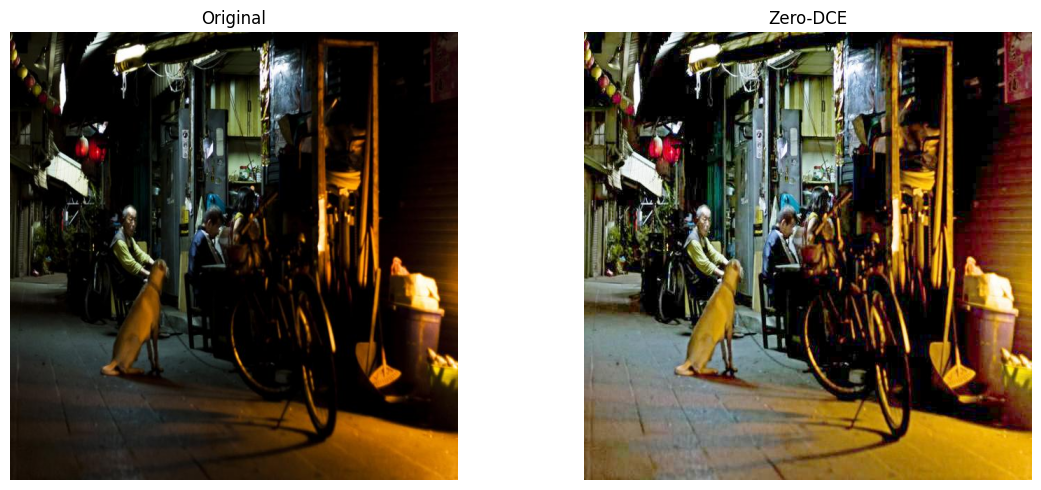

In [83]:
import matplotlib.pyplot as plt

sample_path = test_images[2]

original = Image.open(sample_path).convert("RGB")
enhanced = Image.open(
    ZERO_DCE_DIR / sample_path.name
).convert("RGB")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(original)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(enhanced)
axes[1].set_title("Zero-DCE")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [84]:
zero_dce_paths = sorted(
    p for p in ZERO_DCE_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
)

assert len(zero_dce_paths) == len(test_images), (
    f"Expected {len(test_images)} enhanced images, "
    f"found {len(zero_dce_paths)}"
)

zero_dce_preds, zero_dce_timing = run_detection(
    zero_dce_paths,
    OUTPUT_ROOT / "zero_dce_predictions.json"
)

zero_dce_per_class, zero_dce_metrics = evaluate_predictions(
    zero_dce_preds
)

print("Zero-DCE metrics:")
print(zero_dce_metrics)

print("\nTiming:")
print(zero_dce_timing)

display(zero_dce_per_class.round(4))

Processed 100/734
Processed 200/734
Processed 300/734
Processed 400/734
Processed 500/734
Processed 600/734
Processed 700/734
Processed 734/734
Zero-DCE metrics:
{'mAP50': 0.2940624619171013, 'mAP50_95': 0.15216053124538148, 'mean_precision@0.25': 0.6157433564900205, 'mean_recall@0.25': 0.2509442260498136}

Timing:
{'elapsed_seconds': 9.17986268200002, 'mean_inference_ms': 5.766360769747578}


,class_id,class_name,ground_truths,AP50,AP50_95,precision@0.25,recall@0.25
0,0,Bicycle,139,0.3901,0.2068,0.4831,0.4101
1,1,Boat,93,0.2600,0.1032,0.4528,0.2581
2,2,Bottle,136,0.2188,0.0954,0.5208,0.1838
3,3,Bus,67,0.5011,0.3141,0.6364,0.4179
4,4,Car,282,0.3553,0.1725,0.6880,0.3050
5,5,Cat,78,0.1047,0.0572,0.5455,0.0769
6,6,Chair,229,0.2001,0.0961,0.6512,0.1223
7,8,Dog,90,0.1845,0.0969,0.7333,0.1222
8,9,Motorbike,112,0.3100,0.1738,0.7561,0.2768
9,10,People,868,0.4159,0.2057,0.6903,0.3364


In [85]:
import json
import pandas as pd

baseline_file = Path(
    "/content/exdark_baseline/baseline_summary.json"
)

with open(baseline_file) as f:
    baseline_metrics = json.load(f)

comparison = pd.DataFrame([
    {
        "Method": "Original",
        "mAP50": baseline_metrics["mAP50"],
        "mAP50-95": baseline_metrics["mAP50_95"],
        "Precision": baseline_metrics["mean_precision_at_025"],
        "Recall": baseline_metrics["mean_recall_at_025"],
    },
    {
        "Method": "Gamma",
        "mAP50": gamma_metrics["mAP50"],
        "mAP50-95": gamma_metrics["mAP50_95"],
        "Precision": gamma_metrics["mean_precision@0.25"],
        "Recall": gamma_metrics["mean_recall@0.25"],
    },
    {
        "Method": "CLAHE",
        "mAP50": clahe_metrics["mAP50"],
        "mAP50-95": clahe_metrics["mAP50_95"],
        "Precision": clahe_metrics["mean_precision@0.25"],
        "Recall": clahe_metrics["mean_recall@0.25"],
    },
    {
        "Method": "Zero-DCE",
        "mAP50": zero_dce_metrics["mAP50"],
        "mAP50-95": zero_dce_metrics["mAP50_95"],
        "Precision": zero_dce_metrics["mean_precision@0.25"],
        "Recall": zero_dce_metrics["mean_recall@0.25"],
    },
])

display(comparison.round(4))

comparison.to_csv(
    OUTPUT_ROOT / "enhancement_comparison.csv",
    index=False
)

zero_dce_per_class.to_csv(
    OUTPUT_ROOT / "zero_dce_per_class.csv",
    index=False
)

print("Comparison saved to:", OUTPUT_ROOT)

,Method,mAP50,mAP50-95,Precision,Recall
0,Original,0.4813,0.2590,0.6575,0.4380
1,Gamma,0.4102,0.2148,0.6539,0.3587
2,CLAHE,0.4128,0.2202,0.6370,0.3665
3,Zero-DCE,0.2941,0.1522,0.6157,0.2509


Comparison saved to: /content/exdark_phase2


In [86]:
from pathlib import Path
import zipfile
from google.colab import files

RESULTS_DIR = Path("/content/exdark_phase2")
BASELINE_DIR = Path("/content/exdark_baseline")
ZIP_PATH = Path("/content/low_light_detection_phase2_results.zip")

# Make sure the main comparison table is included.
comparison_path = RESULTS_DIR / "enhancement_comparison.csv"
if not comparison_path.exists():
    comparison_path = RESULTS_DIR / "classical_enhancement_comparison.csv"

assert comparison_path.exists(), (
    "Could not find the comparison CSV. Check /content/exdark_phase2."
)

# Package result files, not the enhanced image folders.
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [RESULTS_DIR, BASELINE_DIR]:
        if folder.exists():
            for p in folder.rglob("*"):
                if not p.is_file():
                    continue
                # Skip enhanced images; they can make the ZIP unnecessarily large.
                if "images" in p.relative_to(folder).parts:
                    continue
                z.write(p, arcname=str(Path(folder.name) / p.relative_to(folder)))

print(f"Comparison table: {comparison_path}")
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
files.download(str(ZIP_PATH))

Comparison table: /content/exdark_phase2/enhancement_comparison.csv
ZIP size: 11.20 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [87]:
from pathlib import Path
import subprocess

SCI_REPO = Path("/content/SCI")

if not SCI_REPO.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/vis-opt-group/SCI.git",
            str(SCI_REPO)
        ],
        check=True
    )

print("Python files:")
for p in SCI_REPO.rglob("*.py"):
    print(p.relative_to(SCI_REPO))

print("\nCheckpoint files:")
checkpoints = []
for pattern in ("*.pth", "*.pt", "*.ckpt"):
    checkpoints.extend(SCI_REPO.rglob(pattern))

if checkpoints:
    for p in checkpoints:
        print(p.relative_to(SCI_REPO), f"({p.stat().st_size / (1024**2):.2f} MB)")
else:
    print("No checkpoints found inside the cloned repository.")

Python files:
TPAMI/loss.py
TPAMI/multi_read_data.py
TPAMI/test.py
TPAMI/utils.py
TPAMI/finetune.py
TPAMI/train.py
TPAMI/model.py
CVPR/loss.py
CVPR/multi_read_data.py
CVPR/test.py
CVPR/utils.py
CVPR/finetune.py
CVPR/train.py
CVPR/model.py

Checkpoint files:
CVPR/weights/difficult.pt (0.04 MB)
CVPR/weights/easy.pt (0.04 MB)
CVPR/weights/medium.pt (0.04 MB)
TPAMI/weights/weights_1_3500.pt (0.10 MB)


In [88]:

from pathlib import Path
import sys
import time
import numpy as np
import torch
from PIL import Image
from torchvision.transforms.functional import to_tensor

SCI_REPO = Path("/content/SCI")
SCI_CVPR = SCI_REPO / "CVPR"
SCI_WEIGHTS = SCI_CVPR / "weights" / "medium.pt"

SCI_OUTPUT_DIR = OUTPUT_ROOT / "sci" / "images"
SCI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert SCI_WEIGHTS.exists(), f"Checkpoint not found: {SCI_WEIGHTS}"
assert len(test_images) > 0, "test_images is empty"

# Import the official SCI model.
if str(SCI_CVPR) not in sys.path:
    sys.path.insert(0, str(SCI_CVPR))

from model import Finetunemodel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Checkpoint:", SCI_WEIGHTS)

sci_model = Finetunemodel(str(SCI_WEIGHTS)).to(device)
sci_model.eval()

sci_paths = []
sci_start = time.time()
skipped = 0

with torch.inference_mode():
    for idx, image_path in enumerate(test_images, start=1):
        image_path = Path(image_path)
        output_path = SCI_OUTPUT_DIR / f"{image_path.stem}.png"

        if output_path.exists():
            skipped += 1
            sci_paths.append(output_path)
            continue

        with Image.open(image_path) as im:
            image = im.convert("RGB")
            image_tensor = to_tensor(image).unsqueeze(0).to(device)

        # The official SCI model returns (illumination map, enhanced image).
        _, enhanced = sci_model(image_tensor)

        enhanced = enhanced.squeeze(0).clamp(0, 1).cpu().numpy()
        enhanced = (enhanced.transpose(1, 2, 0) * 255.0)
        enhanced = np.clip(enhanced, 0, 255).astype(np.uint8)

        Image.fromarray(enhanced).save(output_path)
        sci_paths.append(output_path)

        if idx % 100 == 0 or idx == len(test_images):
            print(f"Processed {idx}/{len(test_images)} images")

sci_enhancement_seconds = time.time() - sci_start

print("\nSCI enhancement complete.")
print("Images:", len(sci_paths))
print("Previously saved and reused:", skipped)
print(f"Enhancement time: {sci_enhancement_seconds:.1f} seconds")
print("Output:", SCI_OUTPUT_DIR)

assert len(sci_paths) == len(test_images)


Device: cuda
Checkpoint: /content/SCI/CVPR/weights/medium.pt
Processed 100/734 images
Processed 200/734 images
Processed 300/734 images
Processed 400/734 images
Processed 500/734 images
Processed 600/734 images
Processed 700/734 images
Processed 734/734 images

SCI enhancement complete.
Images: 734
Previously saved and reused: 0
Enhancement time: 87.7 seconds
Output: /content/exdark_phase2/sci/images


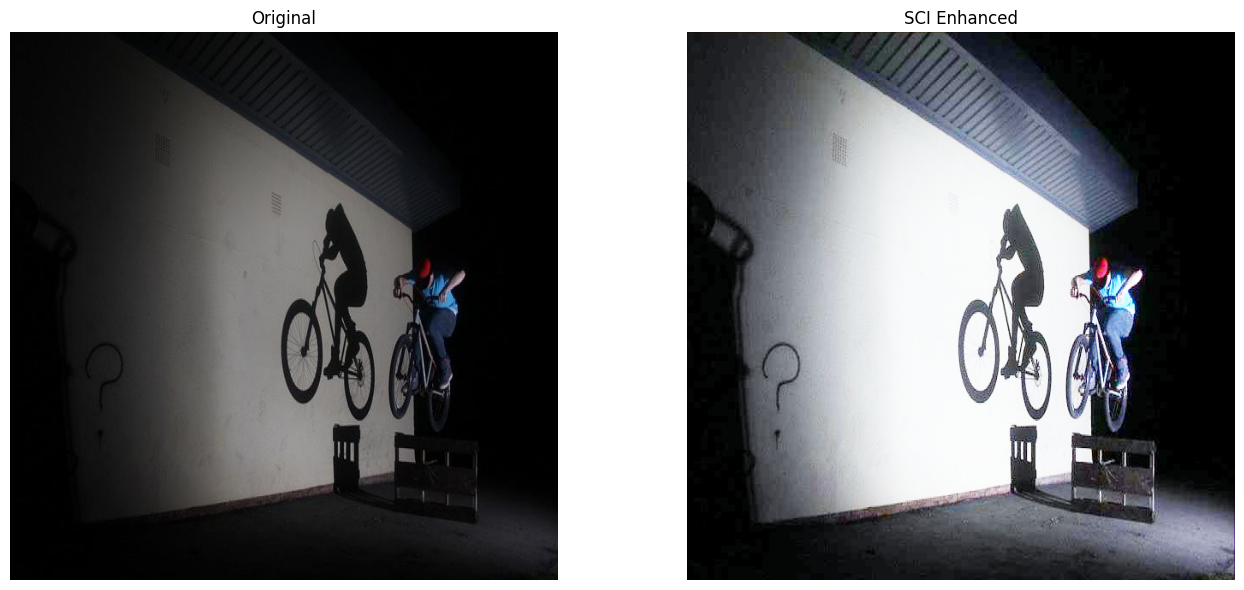

In [98]:

import matplotlib.pyplot as plt

sample_original = Path(test_images[24])
sample_sci = SCI_OUTPUT_DIR / f"{sample_original.stem}.png"

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(Image.open(sample_original).convert("RGB"))
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(Image.open(sample_sci).convert("RGB"))
axes[1].set_title("SCI Enhanced")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [102]:

from pathlib import Path

# Map each enhanced SCI image back to its original test-image filename.
original_by_stem = {
    Path(p).stem: Path(p).name
    for p in test_images
}

sci_preds_fixed = []

for pred in sci_preds:
    pred_fixed = pred.copy()
    pred_name = Path(pred["image"]).name
    pred_stem = Path(pred_name).stem

    if pred_stem not in original_by_stem:
        raise KeyError(
            f"Could not match SCI prediction to original image: {pred_name}"
        )

    pred_fixed["image"] = original_by_stem[pred_stem]
    sci_preds_fixed.append(pred_fixed)

# Evaluate using the original ground-truth image filenames.
sci_per_class, sci_metrics = evaluate_predictions(sci_preds_fixed)

print("SCI metrics:")
display(sci_per_class.round(4))

print("\nSCI summary:")
display(pd.DataFrame([{
    "Method": "SCI",
    "mAP50": sci_metrics["mAP50"],
    "mAP50-95": sci_metrics["mAP50_95"],
    "Precision": sci_metrics["mean_precision@0.25"],
    "Recall": sci_metrics["mean_recall@0.25"],
}]).round(4))

# Save corrected predictions and metrics.
with open(OUTPUT_ROOT / "sci_predictions.json", "w") as f:
    json.dump(sci_preds_fixed, f)

sci_per_class.to_csv(
    OUTPUT_ROOT / "sci_per_class.csv", index=False
)

with open(OUTPUT_ROOT / "sci_summary.json", "w") as f:
    json.dump(sci_metrics, f, indent=2)

print("Saved corrected SCI evaluation results.")


AttributeError: 'str' object has no attribute 'copy'

In [103]:
print("Type of sci_preds:", type(sci_preds))
print("Value preview:", repr(sci_preds)[:1000])

print("\nSCI prediction file exists:",
      (OUTPUT_ROOT / "sci_predictions.json").exists())

pred_file = OUTPUT_ROOT / "sci_predictions.json"
if pred_file.exists():
    with open(pred_file, "r") as f:
        saved = json.load(f)
    print("Saved JSON type:", type(saved))
    print("Saved JSON preview:", repr(saved)[:500])

Type of sci_preds: <class 'dict'>
Value preview: {'2015_00013_jpg.rf.1ccbc5a451029f00e87a4e0d4181841b.png': [{'class_id': 10, 'confidence': 0.7690973877906799, 'bbox': [413.3828125, 300.07763671875, 458.990234375, 454.349365234375]}, {'class_id': 10, 'confidence': 0.4672853648662567, 'bbox': [141.98226928710938, 273.17041015625, 213.26791381835938, 526.8165893554688]}, {'class_id': 10, 'confidence': 0.35670962929725647, 'bbox': [141.3792266845703, 290.59320068359375, 207.5465545654297, 478.28485107421875]}, {'class_id': 10, 'confidence': 0.14431758224964142, 'bbox': [212.58935546875, 523.1083984375, 320.35260009765625, 639.9124755859375]}, {'class_id': 4, 'confidence': 0.14153626561164856, 'bbox': [335.722412109375, 292.1775207519531, 355.808837890625, 319.4698791503906]}, {'class_id': 4, 'confidence': 0.12898102402687073, 'bbox': [444.23638916015625, 310.31805419921875, 461.10540771484375, 325.7620849609375]}, {'class_id': 10, 'confidence': 0.11049710959196091, 'bbox': [177.2511291503

In [105]:

from pathlib import Path
import json
import pandas as pd

# Map image stems to original filenames used by ground_truths.
original_by_stem = {
    Path(p).stem: Path(p).name
    for p in test_images
}

# Convert dict-of-lists to the evaluator's expected list-of-detections format.
sci_preds_fixed = []

for enhanced_name, detections in sci_preds.items():
    stem = Path(enhanced_name).stem

    if stem not in original_by_stem:
        raise KeyError(f"No original image found for {enhanced_name}")

    original_name = original_by_stem[stem]

    for det in detections:
        sci_preds_fixed.append({
            "image": original_name,
            "class_id": det["class_id"],
            "confidence": det["confidence"],
            "bbox": det["bbox"],
        })

print("Enhanced images:", len(sci_preds))
print("Total detections:", len(sci_preds_fixed))
print("Example:", sci_preds_fixed[0] if sci_preds_fixed else "No detections")

# Evaluate with the existing evaluation function.
sci_per_class, sci_metrics = evaluate_predictions(sci_preds_fixed)

print("\nSCI per-class results:")
display(sci_per_class.round(4))

print("\nSCI summary:")
display(pd.DataFrame([{
    "Method": "SCI",
    "mAP50": sci_metrics["mAP50"],
    "mAP50-95": sci_metrics["mAP50_95"],
    "Precision": sci_metrics["mean_precision@0.25"],
    "Recall": sci_metrics["mean_recall@0.25"],
}]).round(4))

# Save results.
with open(OUTPUT_ROOT / "sci_predictions_evaluable.json", "w") as f:
    json.dump(sci_preds_fixed, f)

with open(OUTPUT_ROOT / "sci_summary.json", "w") as f:
    json.dump(sci_metrics, f, indent=2)

sci_per_class.to_csv(OUTPUT_ROOT / "sci_per_class.csv", index=False)

print("\nSaved SCI evaluation outputs to:", OUTPUT_ROOT)


Enhanced images: 734
Total detections: 75474
Example: {'image': '2015_00013_jpg.rf.1ccbc5a451029f00e87a4e0d4181841b.jpg', 'class_id': 10, 'confidence': 0.7690973877906799, 'bbox': [413.3828125, 300.07763671875, 458.990234375, 454.349365234375]}


AttributeError: 'list' object has no attribute 'items'

In [106]:

from pathlib import Path
import json
import pandas as pd

# Map each enhanced image stem to its original filename.
original_by_stem = {
    Path(p).stem: Path(p).name
    for p in test_images
}

# Keep the dictionary structure expected by evaluate_predictions().
sci_preds_fixed = {}

for enhanced_name, detections in sci_preds.items():
    stem = Path(enhanced_name).stem

    if stem not in original_by_stem:
        raise KeyError(f"No original image found for {enhanced_name}")

    original_name = original_by_stem[stem]
    sci_preds_fixed[original_name] = detections

print("Images:", len(sci_preds_fixed))
print("Example:", next(iter(sci_preds_fixed.items())))

# Evaluate using the expected dictionary format.
sci_per_class, sci_metrics = evaluate_predictions(sci_preds_fixed)

print("\nSCI per-class results:")
display(sci_per_class.round(4))

print("\nSCI summary:")
display(pd.DataFrame([{
    "Method": "SCI",
    "mAP50": sci_metrics["mAP50"],
    "mAP50-95": sci_metrics["mAP50_95"],
    "Precision": sci_metrics["mean_precision@0.25"],
    "Recall": sci_metrics["mean_recall@0.25"],
}]).round(4))

# Save the corrected results.
with open(OUTPUT_ROOT / "sci_predictions_evaluable.json", "w") as f:
    json.dump(sci_preds_fixed, f)

with open(OUTPUT_ROOT / "sci_summary.json", "w") as f:
    json.dump(sci_metrics, f, indent=2)

sci_per_class.to_csv(OUTPUT_ROOT / "sci_per_class.csv", index=False)

print("\nSaved SCI evaluation outputs to:", OUTPUT_ROOT)


Images: 734
Example: ('2015_00013_jpg.rf.1ccbc5a451029f00e87a4e0d4181841b.jpg', [{'class_id': 10, 'confidence': 0.7690973877906799, 'bbox': [413.3828125, 300.07763671875, 458.990234375, 454.349365234375]}, {'class_id': 10, 'confidence': 0.4672853648662567, 'bbox': [141.98226928710938, 273.17041015625, 213.26791381835938, 526.8165893554688]}, {'class_id': 10, 'confidence': 0.35670962929725647, 'bbox': [141.3792266845703, 290.59320068359375, 207.5465545654297, 478.28485107421875]}, {'class_id': 10, 'confidence': 0.14431758224964142, 'bbox': [212.58935546875, 523.1083984375, 320.35260009765625, 639.9124755859375]}, {'class_id': 4, 'confidence': 0.14153626561164856, 'bbox': [335.722412109375, 292.1775207519531, 355.808837890625, 319.4698791503906]}, {'class_id': 4, 'confidence': 0.12898102402687073, 'bbox': [444.23638916015625, 310.31805419921875, 461.10540771484375, 325.7620849609375]}, {'class_id': 10, 'confidence': 0.11049710959196091, 'bbox': [177.25112915039062, 272.1536865234375, 199

,class_id,class_name,ground_truths,AP50,AP50_95,precision@0.25,recall@0.25
0,0,Bicycle,139,0.3787,0.1938,0.4737,0.3885
1,1,Boat,93,0.2590,0.1014,0.4630,0.2688
2,2,Bottle,136,0.1634,0.0684,0.4524,0.1397
3,3,Bus,67,0.5005,0.3233,0.6170,0.4328
4,4,Car,282,0.3746,0.1880,0.7252,0.3369
5,5,Cat,78,0.1466,0.0731,0.6250,0.1282
6,6,Chair,229,0.2210,0.1077,0.6531,0.1397
7,8,Dog,90,0.1936,0.0958,0.6667,0.1556
8,9,Motorbike,112,0.3040,0.1689,0.7073,0.2589
9,10,People,868,0.4335,0.2139,0.6568,0.3594



SCI summary:


,Method,mAP50,mAP50-95,Precision,Recall
0,SCI,0.2975,0.1534,0.604,0.2609



Saved SCI evaluation outputs to: /content/exdark_phase2


In [107]:

import json
import pandas as pd
from pathlib import Path

OUTPUT_ROOT = Path("/content/exdark_phase2")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame([
    {"Method": "Original", "mAP50": 0.4813, "mAP50-95": 0.2590,
     "Precision": 0.6575, "Recall": 0.4380},
    {"Method": "Gamma", "mAP50": 0.4102, "mAP50-95": 0.2148,
     "Precision": 0.6539, "Recall": 0.3587},
    {"Method": "CLAHE", "mAP50": 0.4128, "mAP50-95": 0.2202,
     "Precision": 0.6370, "Recall": 0.3665},
    {"Method": "Zero-DCE", "mAP50": 0.2941, "mAP50-95": 0.1522,
     "Precision": 0.6157, "Recall": 0.2509},
    {"Method": "SCI", "mAP50": 0.2975, "mAP50-95": 0.1534,
     "Precision": 0.6040, "Recall": 0.2609},
])

comparison.to_csv(
    OUTPUT_ROOT / "final_enhancement_comparison.csv",
    index=False
)

with open(OUTPUT_ROOT / "final_enhancement_comparison.json", "w") as f:
    json.dump(comparison.to_dict(orient="records"), f, indent=2)

display(comparison.round(4))
print("Saved to:", OUTPUT_ROOT / "final_enhancement_comparison.csv")


,Method,mAP50,mAP50-95,Precision,Recall
0,Original,0.4813,0.2590,0.6575,0.4380
1,Gamma,0.4102,0.2148,0.6539,0.3587
2,CLAHE,0.4128,0.2202,0.6370,0.3665
3,Zero-DCE,0.2941,0.1522,0.6157,0.2509
4,SCI,0.2975,0.1534,0.6040,0.2609


Saved to: /content/exdark_phase2/final_enhancement_comparison.csv


In [108]:

from pathlib import Path
import yaml
import torch
import ultralytics

DATA_YAML = Path("/content/ExDark/exdark.yaml")
BASELINE_SUMMARY = Path("/content/exdark_baseline/baseline_summary.json")
OUTPUT_DIR = Path("/content/exdark_finetune")
RUN_NAME = "yolov8n_exdark_original"

assert DATA_YAML.exists(), f"Dataset YAML not found: {DATA_YAML}"
assert BASELINE_SUMMARY.exists(), "Your pretrained baseline summary is missing."
assert torch.cuda.is_available(), (
    "GPU is not enabled. In Colab, go to Runtime > Change runtime type > T4 GPU (or another available GPU)."
)

with open(DATA_YAML, "r") as f:
    data_cfg = yaml.safe_load(f)

dataset_root = Path(data_cfg["path"])
if not dataset_root.is_absolute():
    dataset_root = (DATA_YAML.parent / dataset_root).resolve()

def resolve_split(split):
    p = Path(data_cfg[split])
    return p if p.is_absolute() else (dataset_root / p).resolve()

train_dir = resolve_split("train")
val_dir = resolve_split("val")
test_dir = resolve_split("test")

print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Dataset root:", dataset_root)
print("Train images:", train_dir)
print("Validation images:", val_dir)
print("Test images:", test_dir)
print("Number of classes:", data_cfg["nc"])
print("Class names:", data_cfg["names"])

for split_name, image_dir in [
    ("train", train_dir),
    ("val", val_dir),
    ("test", test_dir),
]:
    assert image_dir.is_dir(), f"{split_name} image directory missing: {image_dir}"
    image_count = sum(
        1 for p in image_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )
    print(f"{split_name}: {image_count} images")

assert data_cfg["nc"] == 12, "Expected 12 ExDark classes."
assert len(data_cfg["names"]) == 12, "Class names and nc do not match."

# Use the exact test-image list from your existing baseline experiment.
assert "test_images" in globals() and len(test_images) > 0, (
    "The existing test_images list is missing. Keep using the same Colab runtime."
)
print("Images in the existing baseline test list:", len(test_images))


Ultralytics: 8.4.190
GPU: Tesla T4
Dataset root: /content/ExDark/data
Train images: /content/ExDark/data/train/images
Validation images: /content/ExDark/data/valid/images
Test images: /content/ExDark/data/test/images
Number of classes: 12
Class names: ['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']
train: 5874 images
val: 736 images
test: 734 images
Images in the existing baseline test list: 734


In [109]:

from pathlib import Path
from ultralytics import YOLO

OUTPUT_DIR = Path("/content/exdark_finetune")
RUN_NAME = "yolov8n_exdark_original"
BEST_PT = OUTPUT_DIR / RUN_NAME / "weights" / "best.pt"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if BEST_PT.exists():
    print("Existing best checkpoint found. Reusing it:")
    print(BEST_PT)
else:
    model_to_train = YOLO("yolov8n.pt")

    train_results = model_to_train.train(
        data=str(DATA_YAML),
        epochs=50,
        patience=10,
        imgsz=640,
        batch=8,
        workers=2,
        device=0,
        project=str(OUTPUT_DIR),
        name=RUN_NAME,
        exist_ok=True,
        pretrained=True,
        optimizer="auto",
        seed=42,
        deterministic=True,
        cache=False,
        plots=True,
        save=True,
        verbose=True,
    )

    print("Training finished.")
    print("Run directory:", train_results.save_dir)

assert BEST_PT.exists(), f"Best checkpoint not found: {BEST_PT}"
print("Best model:", BEST_PT)
print(f"Checkpoint size: {BEST_PT.stat().st_size / (1024**2):.2f} MB")


Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ExDark/exdark.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_exdark_original, nbs=64, nms=None, opset=None, optimize

In [110]:

from ultralytics import YOLO

fine_tuned_model = YOLO(str(BEST_PT))

print("Loaded:", BEST_PT)
print("Model class names:")
print(fine_tuned_model.names)


Loaded: /content/exdark_finetune/yolov8n_exdark_original/weights/best.pt
Model class names:
{0: 'Bicycle', 1: 'Boat', 2: 'Bottle', 3: 'Bus', 4: 'Car', 5: 'Cat', 6: 'Chair', 7: 'Cup', 8: 'Dog', 9: 'Motorbike', 10: 'People', 11: 'Table'}


In [111]:

import json
import time
from pathlib import Path

import torch

FINE_TUNED_PREDS_PATH = OUTPUT_DIR / "fine_tuned_test_predictions.json"

# Reuse previously saved predictions if this step has already completed.
if FINE_TUNED_PREDS_PATH.exists():
    with open(FINE_TUNED_PREDS_PATH, "r") as f:
        fine_tuned_predictions = json.load(f)
    print("Loaded saved predictions.")
else:
    fine_tuned_predictions = {
        Path(p).name: []
        for p in test_images
    }

    inference_start = time.time()
    chunk_size = 4

    for start in range(0, len(test_images), chunk_size):
        batch_paths = test_images[start:start + chunk_size]

        results = fine_tuned_model.predict(
            source=[str(p) for p in batch_paths],
            imgsz=640,
            conf=0.001,
            iou=0.7,
            max_det=300,
            device=0,
            verbose=False,
            save=False,
        )

        for result in results:
            image_name = Path(result.path).name
            detections = []

            if result.boxes is not None and len(result.boxes) > 0:
                boxes_xyxy = result.boxes.xyxy.cpu().tolist()
                confidences = result.boxes.conf.cpu().tolist()
                class_ids = result.boxes.cls.cpu().tolist()

                for bbox, confidence, class_id in zip(
                    boxes_xyxy, confidences, class_ids
                ):
                    detections.append({
                        "class_id": int(class_id),
                        "confidence": float(confidence),
                        "bbox": [float(v) for v in bbox],
                    })

            fine_tuned_predictions[image_name] = detections

        completed = min(start + len(batch_paths), len(test_images))
        if completed % 100 < chunk_size or completed == len(test_images):
            print(f"Processed {completed}/{len(test_images)} images")

    inference_seconds = time.time() - inference_start

    with open(FINE_TUNED_PREDS_PATH, "w") as f:
        json.dump(fine_tuned_predictions, f)

    print(f"Inference time: {inference_seconds:.1f} seconds")

assert len(fine_tuned_predictions) == len(test_images)
print("Test images evaluated:", len(fine_tuned_predictions))
print(
    "Total detections:",
    sum(len(items) for items in fine_tuned_predictions.values())
)
print("Predictions saved to:", FINE_TUNED_PREDS_PATH)


Processed 100/734 images
Processed 200/734 images
Processed 300/734 images
Processed 400/734 images
Processed 500/734 images
Processed 600/734 images
Processed 700/734 images
Processed 734/734 images
Inference time: 7.9 seconds
Test images evaluated: 734
Total detections: 56514
Predictions saved to: /content/exdark_finetune/fine_tuned_test_predictions.json


In [112]:

# Ensure the evaluation inputs from your baseline experiment still exist.
required_variables = [
    "ground_truths",
    "EVALUATED_CLASSES",
    "evaluate_predictions",
]

for name in required_variables:
    assert name in globals(), (
        f"{name} is missing. This code expects the same Colab runtime."
    )

assert isinstance(fine_tuned_predictions, dict)
assert all(isinstance(v, list) for v in fine_tuned_predictions.values())

fine_tuned_per_class, fine_tuned_metrics = evaluate_predictions(
    fine_tuned_predictions
)

print("Fine-tuned YOLOv8n — per-class results")
display(fine_tuned_per_class.round(4))

print("\nFine-tuned YOLOv8n — summary")
display(pd.DataFrame([{
    "Method": "Fine-tuned YOLOv8n",
    "mAP50": fine_tuned_metrics["mAP50"],
    "mAP50-95": fine_tuned_metrics["mAP50_95"],
    "Precision": fine_tuned_metrics["mean_precision@0.25"],
    "Recall": fine_tuned_metrics["mean_recall@0.25"],
}]).round(4))

fine_tuned_per_class.to_csv(
    OUTPUT_DIR / "fine_tuned_per_class.csv",
    index=False
)

with open(OUTPUT_DIR / "fine_tuned_summary.json", "w") as f:
    json.dump(fine_tuned_metrics, f, indent=2)

print("Evaluation results saved to:", OUTPUT_DIR)


Fine-tuned YOLOv8n — per-class results


,class_id,class_name,ground_truths,AP50,AP50_95,precision@0.25,recall@0.25
0,0,Bicycle,139,0.7346,0.4874,0.7405,0.6978
1,1,Boat,93,0.7520,0.3919,0.6396,0.7634
2,2,Bottle,136,0.6552,0.4038,0.6489,0.6250
3,3,Bus,67,0.8110,0.6156,0.6933,0.7761
4,4,Car,282,0.7617,0.4936,0.6933,0.7376
5,5,Cat,78,0.6832,0.4321,0.6364,0.7179
6,6,Chair,229,0.6367,0.3506,0.5851,0.6157
7,8,Dog,90,0.6477,0.4529,0.5962,0.6889
8,9,Motorbike,112,0.7453,0.4478,0.5503,0.7321
9,10,People,868,0.7426,0.4123,0.6857,0.7039



Fine-tuned YOLOv8n — summary


,Method,mAP50,mAP50-95,Precision,Recall
0,Fine-tuned YOLOv8n,0.717,0.4488,0.6469,0.7059


Evaluation results saved to: /content/exdark_finetune


In [113]:

import json
import pandas as pd
from pathlib import Path

with open(BASELINE_SUMMARY, "r") as f:
    baseline_metrics = json.load(f)

comparison = pd.DataFrame([
    {
        "Model": "Pretrained YOLOv8n",
        "mAP50": baseline_metrics["mAP50"],
        "mAP50-95": baseline_metrics["mAP50_95"],
        "Precision": baseline_metrics["mean_precision_at_025"],
        "Recall": baseline_metrics["mean_recall_at_025"],
    },
    {
        "Model": "Fine-tuned YOLOv8n",
        "mAP50": fine_tuned_metrics["mAP50"],
        "mAP50-95": fine_tuned_metrics["mAP50_95"],
        "Precision": fine_tuned_metrics["mean_precision@0.25"],
        "Recall": fine_tuned_metrics["mean_recall@0.25"],
    },
])

baseline_map50 = comparison.loc[
    comparison["Model"] == "Pretrained YOLOv8n", "mAP50"
].iloc[0]

fine_tuned_map50 = comparison.loc[
    comparison["Model"] == "Fine-tuned YOLOv8n", "mAP50"
].iloc[0]

percentage_change = (
    (fine_tuned_map50 - baseline_map50) / baseline_map50 * 100
)

comparison["mAP50 change vs baseline (%)"] = [
    0.0,
    percentage_change,
]

comparison.to_csv(
    OUTPUT_DIR / "pretrained_vs_finetuned.csv",
    index=False
)

display(comparison.round(4))

print(f"mAP50 change: {percentage_change:+.2f}%")
print("Comparison saved to:", OUTPUT_DIR / "pretrained_vs_finetuned.csv")


,Model,mAP50,mAP50-95,Precision,Recall,mAP50 change vs baseline (%)
0,Pretrained YOLOv8n,0.4813,0.2590,0.6575,0.4380,0.0000
1,Fine-tuned YOLOv8n,0.7170,0.4488,0.6469,0.7059,48.9872


mAP50 change: +48.99%
Comparison saved to: /content/exdark_finetune/pretrained_vs_finetuned.csv


In [114]:

from pathlib import Path
import zipfile
from google.colab import files

BACKUP_ZIP = Path("/content/exdark_finetune_results.zip")

with zipfile.ZipFile(BACKUP_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    # Include fine-tuning weights.
    weights_dir = OUTPUT_DIR / RUN_NAME / "weights"
    if weights_dir.exists():
        for p in weights_dir.rglob("*"):
            if p.is_file():
                z.write(p, arcname=str(p.relative_to(OUTPUT_DIR)))

    # Include metrics, predictions, and training outputs.
    for p in OUTPUT_DIR.rglob("*"):
        if not p.is_file():
            continue
        if "images" in p.relative_to(OUTPUT_DIR).parts:
            continue
        z.write(p, arcname=str(p.relative_to(OUTPUT_DIR)))

print(f"Backup size: {BACKUP_ZIP.stat().st_size / (1024**2):.2f} MB")
files.download(str(BACKUP_ZIP))


/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'yolov8n_exdark_original/weights/last.pt'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'yolov8n_exdark_original/weights/best.pt'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


Backup size: 32.21 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [115]:

from pathlib import Path
import zipfile
from google.colab import files

BASELINE_DIR = Path("/content/exdark_baseline")
FINETUNE_DIR = Path("/content/exdark_finetune")
PHASE2_DIR = Path("/content/exdark_phase2")

BEST_MODEL = FINETUNE_DIR / "yolov8n_exdark_original" / "weights" / "best.pt"
LAST_MODEL = FINETUNE_DIR / "yolov8n_exdark_original" / "weights" / "last.pt"
BACKUP_ZIP = Path("/content/low_light_detection_results_backup.zip")

assert BEST_MODEL.exists(), f"Best model not found: {BEST_MODEL}"
assert (FINETUNE_DIR / "pretrained_vs_finetuned.csv").exists(), (
    "Comparison CSV is missing. Run the earlier comparison cell first."
)

folders = [
    ("fine_tuning", FINETUNE_DIR),
    ("baseline", BASELINE_DIR),
    ("enhancement_experiments", PHASE2_DIR),
]

with zipfile.ZipFile(BACKUP_ZIP, "w", zipfile.ZIP_DEFLATED) as archive:
    added = []

    for archive_folder, folder in folders:
        if not folder.exists():
            print(f"Skipping missing folder: {folder}")
            continue

        for path in folder.rglob("*"):
            if not path.is_file():
                continue

            relative = path.relative_to(folder)

            # Exclude image folders to keep the backup reasonably small.
            if "images" in relative.parts:
                continue

            # Avoid adding an existing backup ZIP to itself.
            if path == BACKUP_ZIP:
                continue

            archive_name = Path(archive_folder) / relative
            archive.write(path, arcname=str(archive_name))
            added.append(str(archive_name))

print("Files included:", len(added))
print(f"Backup size: {BACKUP_ZIP.stat().st_size / (1024**2):.2f} MB")
print("Best checkpoint:", BEST_MODEL)
print("Last checkpoint exists:", LAST_MODEL.exists())
print("Backup:", BACKUP_ZIP)

files.download(str(BACKUP_ZIP))


Files included: 51
Backup size: 37.91 MB
Best checkpoint: /content/exdark_finetune/yolov8n_exdark_original/weights/best.pt
Last checkpoint exists: True
Backup: /content/low_light_detection_results_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [116]:

import json
import pandas as pd
from pathlib import Path

BASELINE_PREDICTIONS_PATH = Path(
    "/content/exdark_baseline/baseline_predictions.json"
)
FINETUNED_PREDICTIONS_PATH = Path(
    "/content/exdark_finetune/fine_tuned_test_predictions.json"
)

assert BASELINE_PREDICTIONS_PATH.exists(), (
    f"Missing baseline predictions: {BASELINE_PREDICTIONS_PATH}"
)
assert FINETUNED_PREDICTIONS_PATH.exists(), (
    f"Missing fine-tuned predictions: {FINETUNED_PREDICTIONS_PATH}"
)
assert "ground_truths" in globals() and "EVALUATED_CLASSES" in globals()
assert "evaluate_predictions" in globals()

with open(BASELINE_PREDICTIONS_PATH, "r") as f:
    baseline_preds_for_eval = json.load(f)

with open(FINETUNED_PREDICTIONS_PATH, "r") as f:
    finetuned_preds_for_eval = json.load(f)

assert isinstance(baseline_preds_for_eval, dict)
assert isinstance(finetuned_preds_for_eval, dict)

# Evaluate the pretrained baseline.
baseline_per_class, baseline_recomputed_metrics = evaluate_predictions(
    baseline_preds_for_eval
)

# Evaluate the fine-tuned model.
finetuned_per_class, finetuned_recomputed_metrics = evaluate_predictions(
    finetuned_preds_for_eval
)

print("Baseline per-class columns:", list(baseline_per_class.columns))
print("Fine-tuned per-class columns:", list(finetuned_per_class.columns))

print("\nPRETRAINED YOLOv8n — per class")
display(baseline_per_class.round(4))

print("\nFINE-TUNED YOLOv8n — per class")
display(finetuned_per_class.round(4))

# Save the recomputed per-class tables.
OUT = Path("/content/exdark_finetune")
baseline_per_class.to_csv(OUT / "baseline_per_class_recomputed.csv", index=False)
finetuned_per_class.to_csv(OUT / "fine_tuned_per_class.csv", index=False)

with open(OUT / "baseline_metrics_recomputed.json", "w") as f:
    json.dump(baseline_recomputed_metrics, f, indent=2)

with open(OUT / "fine_tuned_summary.json", "w") as f:
    json.dump(finetuned_recomputed_metrics, f, indent=2)

print("Saved recomputed per-class metrics.")


Baseline per-class columns: ['class_id', 'class_name', 'ground_truths', 'AP50', 'AP50_95', 'precision@0.25', 'recall@0.25']
Fine-tuned per-class columns: ['class_id', 'class_name', 'ground_truths', 'AP50', 'AP50_95', 'precision@0.25', 'recall@0.25']

PRETRAINED YOLOv8n — per class


,class_id,class_name,ground_truths,AP50,AP50_95,precision@0.25,recall@0.25
0,0,Bicycle,139,0.5019,0.2542,0.5303,0.5036
1,1,Boat,93,0.3327,0.1278,0.5417,0.2796
2,2,Bottle,136,0.3807,0.1708,0.5495,0.3676
3,3,Bus,67,0.7087,0.4809,0.7679,0.6418
4,4,Car,282,0.5410,0.2811,0.7444,0.4752
5,5,Cat,78,0.4723,0.2740,0.7391,0.4359
6,6,Chair,229,0.4072,0.2085,0.5862,0.3712
7,8,Dog,90,0.4114,0.2208,0.7333,0.3667
8,9,Motorbike,112,0.4604,0.2640,0.6912,0.4196
9,10,People,868,0.5962,0.3075,0.6912,0.5184



FINE-TUNED YOLOv8n — per class


,class_id,class_name,ground_truths,AP50,AP50_95,precision@0.25,recall@0.25
0,0,Bicycle,139,0.7346,0.4874,0.7405,0.6978
1,1,Boat,93,0.7520,0.3919,0.6396,0.7634
2,2,Bottle,136,0.6552,0.4038,0.6489,0.6250
3,3,Bus,67,0.8110,0.6156,0.6933,0.7761
4,4,Car,282,0.7617,0.4936,0.6933,0.7376
5,5,Cat,78,0.6832,0.4321,0.6364,0.7179
6,6,Chair,229,0.6367,0.3506,0.5851,0.6157
7,8,Dog,90,0.6477,0.4529,0.5962,0.6889
8,9,Motorbike,112,0.7453,0.4478,0.5503,0.7321
9,10,People,868,0.7426,0.4123,0.6857,0.7039


Saved recomputed per-class metrics.


In [117]:

# Find a common class identifier.
baseline_cols = {c.lower(): c for c in baseline_per_class.columns}
finetuned_cols = {c.lower(): c for c in finetuned_per_class.columns}

preferred_keys = ["class_id", "class_name", "class", "name"]
join_key = next(
    (
        baseline_cols[k]
        for k in preferred_keys
        if k in baseline_cols
        and k in finetuned_cols
        and baseline_cols[k] == finetuned_cols[k]
    ),
    None
)

if join_key is None:
    raise ValueError(
        "Could not identify a shared class column. "
        f"Baseline columns: {list(baseline_per_class.columns)}; "
        f"fine-tuned columns: {list(finetuned_per_class.columns)}"
    )

# Identify metrics that are numeric in both tables, excluding the class ID.
metric_cols = []
for col in baseline_per_class.columns:
    if col == join_key or col not in finetuned_per_class.columns:
        continue

    if (
        pd.api.types.is_numeric_dtype(baseline_per_class[col])
        and pd.api.types.is_numeric_dtype(finetuned_per_class[col])
    ):
        metric_cols.append(col)

if not metric_cols:
    raise ValueError("No shared numeric per-class metric columns were found.")

baseline_table = baseline_per_class[[join_key] + metric_cols].copy()
finetuned_table = finetuned_per_class[[join_key] + metric_cols].copy()

baseline_table = baseline_table.rename(
    columns={c: f"{c}_baseline" for c in metric_cols}
)
finetuned_table = finetuned_table.rename(
    columns={c: f"{c}_finetuned" for c in metric_cols}
)

class_comparison = baseline_table.merge(
    finetuned_table,
    on=join_key,
    how="outer",
    indicator=True
)

print("Merge status:")
print(class_comparison["_merge"].value_counts())

class_comparison.drop(columns="_merge", inplace=True)

for metric in metric_cols:
    class_comparison[f"{metric}_change"] = (
        class_comparison[f"{metric}_finetuned"]
        - class_comparison[f"{metric}_baseline"]
    )

# Sort by the change in AP50 if the evaluator has an AP50-like metric.
ap50_candidates = [
    c for c in metric_cols
    if c.lower().replace("_", "").replace("-", "") in {"ap50", "map50"}
]

if ap50_candidates:
    ap50_col = ap50_candidates[0]
    class_comparison = class_comparison.sort_values(
        f"{ap50_col}_change", ascending=False
    )

class_comparison.to_csv(
    OUT / "per_class_baseline_vs_finetuned.csv",
    index=False
)

display(class_comparison.round(4))
print("Saved:", OUT / "per_class_baseline_vs_finetuned.csv")


Merge status:
_merge
both          10
left_only      0
right_only     0
Name: count, dtype: int64


/tmp/ipykernel_1002/1064038943.py:59: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  class_comparison.drop(columns="_merge", inplace=True)


,class_id,ground_truths_baseline,AP50_baseline,AP50_95_baseline,precision@0.25_baseline,recall@0.25_baseline,ground_truths_finetuned,AP50_finetuned,AP50_95_finetuned,precision@0.25_finetuned,recall@0.25_finetuned,ground_truths_change,AP50_change,AP50_95_change,precision@0.25_change,recall@0.25_change
1,1,93,0.3327,0.1278,0.5417,0.2796,93,0.7520,0.3919,0.6396,0.7634,0,0.4194,0.2641,0.0980,0.4839
8,9,112,0.4604,0.2640,0.6912,0.4196,112,0.7453,0.4478,0.5503,0.7321,0,0.2849,0.1839,-0.1408,0.3125
2,2,136,0.3807,0.1708,0.5495,0.3676,136,0.6552,0.4038,0.6489,0.6250,0,0.2744,0.2330,0.0994,0.2574
7,8,90,0.4114,0.2208,0.7333,0.3667,90,0.6477,0.4529,0.5962,0.6889,0,0.2363,0.2321,-0.1372,0.3222
0,0,139,0.5019,0.2542,0.5303,0.5036,139,0.7346,0.4874,0.7405,0.6978,0,0.2327,0.2332,0.2102,0.1942
6,6,229,0.4072,0.2085,0.5862,0.3712,229,0.6367,0.3506,0.5851,0.6157,0,0.2296,0.1421,-0.0011,0.2445
4,4,282,0.5410,0.2811,0.7444,0.4752,282,0.7617,0.4936,0.6933,0.7376,0,0.2207,0.2126,-0.0511,0.2624
5,5,78,0.4723,0.2740,0.7391,0.4359,78,0.6832,0.4321,0.6364,0.7179,0,0.2109,0.1580,-0.1028,0.2821
9,10,868,0.5962,0.3075,0.6912,0.5184,868,0.7426,0.4123,0.6857,0.7039,0,0.1464,0.1048,-0.0055,0.1855
3,3,67,0.7087,0.4809,0.7679,0.6418,67,0.8110,0.6156,0.6933,0.7761,0,0.1023,0.1347,-0.0745,0.1343


Saved: /content/exdark_finetune/per_class_baseline_vs_finetuned.csv


In [118]:

if not ap50_candidates:
    print(
        "No AP50-named column was found. "
        "Review the per-class comparison table above."
    )
else:
    change_col = f"{ap50_col}_change"

    print("TOP 5 improvements in", ap50_col)
    display(
        class_comparison[
            [join_key, f"{ap50_col}_baseline",
             f"{ap50_col}_finetuned", change_col]
        ].sort_values(change_col, ascending=False).head(5).round(4)
    )

    print("BOTTOM 5 changes in", ap50_col)
    display(
        class_comparison[
            [join_key, f"{ap50_col}_baseline",
             f"{ap50_col}_finetuned", change_col]
        ].sort_values(change_col, ascending=True).head(5).round(4)
    )


TOP 5 improvements in AP50


,class_id,AP50_baseline,AP50_finetuned,AP50_change
1,1,0.3327,0.7520,0.4194
8,9,0.4604,0.7453,0.2849
2,2,0.3807,0.6552,0.2744
7,8,0.4114,0.6477,0.2363
0,0,0.5019,0.7346,0.2327


BOTTOM 5 changes in AP50


,class_id,AP50_baseline,AP50_finetuned,AP50_change
3,3,0.7087,0.8110,0.1023
9,10,0.5962,0.7426,0.1464
5,5,0.4723,0.6832,0.2109
4,4,0.5410,0.7617,0.2207
6,6,0.4072,0.6367,0.2296


In [119]:

from pathlib import Path
import zipfile
from google.colab import files

BASELINE_DIR = Path("/content/exdark_baseline")
FINETUNE_DIR = Path("/content/exdark_finetune")
PHASE2_DIR = Path("/content/exdark_phase2")

BEST_MODEL = FINETUNE_DIR / "yolov8n_exdark_original" / "weights" / "best.pt"
LAST_MODEL = FINETUNE_DIR / "yolov8n_exdark_original" / "weights" / "last.pt"
BACKUP_ZIP = Path("/content/low_light_detection_results_backup.zip")

assert BEST_MODEL.exists(), f"Best model not found: {BEST_MODEL}"
assert (FINETUNE_DIR / "pretrained_vs_finetuned.csv").exists(), (
    "Comparison CSV is missing. Run the earlier comparison cell first."
)

folders = [
    ("fine_tuning", FINETUNE_DIR),
    ("baseline", BASELINE_DIR),
    ("enhancement_experiments", PHASE2_DIR),
]

with zipfile.ZipFile(BACKUP_ZIP, "w", zipfile.ZIP_DEFLATED) as archive:
    added = []

    for archive_folder, folder in folders:
        if not folder.exists():
            print(f"Skipping missing folder: {folder}")
            continue

        for path in folder.rglob("*"):
            if not path.is_file():
                continue

            relative = path.relative_to(folder)

            # Exclude image folders to keep the backup reasonably small.
            if "images" in relative.parts:
                continue

            # Avoid adding an existing backup ZIP to itself.
            if path == BACKUP_ZIP:
                continue

            archive_name = Path(archive_folder) / relative
            archive.write(path, arcname=str(archive_name))
            added.append(str(archive_name))

print("Files included:", len(added))
print(f"Backup size: {BACKUP_ZIP.stat().st_size / (1024**2):.2f} MB")
print("Best checkpoint:", BEST_MODEL)
print("Last checkpoint exists:", LAST_MODEL.exists())
print("Backup:", BACKUP_ZIP)

files.download(str(BACKUP_ZIP))


Files included: 54
Backup size: 37.91 MB
Best checkpoint: /content/exdark_finetune/yolov8n_exdark_original/weights/best.pt
Last checkpoint exists: True
Backup: /content/low_light_detection_results_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [120]:
import os
import json
import pandas as pd

# All 12 ExDark classes, in the dataset's original order
EXDARK_NAMES = [
    "Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
    "Chair", "Cup", "Dog", "Motorbike", "People", "Table"
]
EVALUATED_CLASSES = list(range(12))

# Load the existing fine-tuned model's test predictions
predictions_path = (
    "/content/exdark_finetune/fine_tuned_test_predictions.json"
)

with open(predictions_path, "r") as f:
    fine_tuned_predictions = json.load(f)

print("Test images with predictions:", len(fine_tuned_predictions))
print("Classes being evaluated:", len(EVALUATED_CLASSES))

# Evaluate all 12 classes using your existing evaluator
results_12 = evaluate_predictions(fine_tuned_predictions)

print("\nEvaluation output:")
print(results_12)

Test images with predictions: 734
Classes being evaluated: 12

Evaluation output:
(    class_id class_name  ground_truths      AP50   AP50_95  precision@0.25  \
0          0    Bicycle            139  0.734581  0.487372        0.740458   
1          1       Boat             93  0.752027  0.391899        0.639640   
2          2     Bottle            136  0.655158  0.403816        0.648855   
3          3        Bus             67  0.810996  0.615641        0.693333   
4          4        Car            282  0.761741  0.493615        0.693333   
5          5        Cat             78  0.683211  0.432083        0.636364   
6          6      Chair            229  0.636712  0.350602        0.585062   
7          7        Cup              0       NaN       NaN             NaN   
8          8        Dog             90  0.647742  0.452888        0.596154   
9          9  Motorbike            112  0.745304  0.447837        0.550336   
10        10     People            868  0.742555  0.412346 

In [121]:
import os
import zipfile
from google.colab import files

# Save the 12-class evaluation output as a readable text file
results_txt = "/content/exdark_finetune/all_12_class_evaluation.txt"

with open(results_txt, "w") as f:
    f.write(repr(results_12))

# Create a backup archive
backup_path = "/content/low_light_detection_results_backup.zip"

source_dirs = [
    "/content/exdark_baseline",
    "/content/exdark_phase2",
    "/content/exdark_finetune",
]

with zipfile.ZipFile(backup_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for source_dir in source_dirs:
        if not os.path.isdir(source_dir):
            print("Skipping missing directory:", source_dir)
            continue

        for root, dirs, filenames in os.walk(source_dir):
            # Exclude generated image collections to reduce ZIP size
            dirs[:] = [
                d for d in dirs
                if d.lower() != "images"
            ]

            for filename in filenames:
                full_path = os.path.join(root, filename)
                archive_path = os.path.relpath(full_path, "/content")
                zf.write(full_path, archive_path)

print("Backup created:", backup_path)
print(f"ZIP size: {os.path.getsize(backup_path) / (1024**2):.2f} MB")

# Download the archive to your computer
files.download(backup_path)

Backup created: /content/low_light_detection_results_backup.zip
ZIP size: 37.91 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [139]:
from pathlib import Path
from PIL import Image
import random
import matplotlib.pyplot as plt

BASE = Path("/content")
OUTPUT_DIR = BASE / "report_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Image folders
folders = {
    "Original": Path("/content/ExDark/data/test/images"),
    "Gamma": Path("/content/exdark_phase2/gamma/images"),
    "CLAHE": Path("/content/exdark_phase2/clahe/images"),
    "Zero-DCE": Path("/content/exdark_phase2/zero_dce/images"),
    "SCI": Path("/content/exdark_phase2/sci/images"),
}

# Check that all folders exist
for name, folder in folders.items():
    if not folder.is_dir():
        raise FileNotFoundError(
            f"{name} image folder not found: {folder}\n"
            "Check the folder path before running this cell."
        )

# Index images by filename (without extension)
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def index_images(folder):
    result = {}
    for path in folder.iterdir():
        if path.is_file() and path.suffix.lower() in valid_extensions:
            result.setdefault(path.stem.lower(), path)
    return result

image_indexes = {
    name: index_images(folder)
    for name, folder in folders.items()
}

# Find images available in every method's folder
common_stems = sorted(
    set.intersection(
        *(set(index.keys()) for index in image_indexes.values())
    )
)

if len(common_stems) < 3:
    raise RuntimeError(
        f"Only {len(common_stems)} matching images found across all folders. "
        "Check the filenames and folder paths."
    )

# Randomly select 3 images (reproducible selection)
random.seed(40)
selected_stems = random.sample(common_stems, 3)

print("Selected 3 random images:")
for i, stem in enumerate(selected_stems, start=1):
    print(f"{i}. {stem}")

# Create one comparison figure for each enhancement method
comparisons = [
    ("Gamma", "original_vs_gamma.png"),
    ("CLAHE", "original_vs_clahe.png"),
    ("Zero-DCE", "original_vs_zero_dce.png"),
    ("SCI", "original_vs_sci.png"),
]

for enhanced_name, filename in comparisons:
    fig, axes = plt.subplots(3, 2, figsize=(12, 15))

    for row, stem in enumerate(selected_stems):
        original_path = image_indexes["Original"][stem]
        enhanced_path = image_indexes[enhanced_name][stem]

        with Image.open(original_path) as im:
            original = im.convert("RGB").copy()

        with Image.open(enhanced_path) as im:
            enhanced = im.convert("RGB").copy()

        axes[row, 0].imshow(original)
        axes[row, 0].set_title("Original", fontsize=13)
        axes[row, 0].axis("off")

        axes[row, 1].imshow(enhanced)
        axes[row, 1].set_title(enhanced_name, fontsize=13)
        axes[row, 1].axis("off")

    fig.suptitle(
        f"Original vs. {enhanced_name}:",
        fontsize=16
    )
    fig.tight_layout(rect=[0, 0, 1, 0.97])

    save_path = OUTPUT_DIR / filename
    fig.savefig(save_path, dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")

print("\nAll four comparison figures have been saved.")

Output hidden; open in https://colab.research.google.com to view.

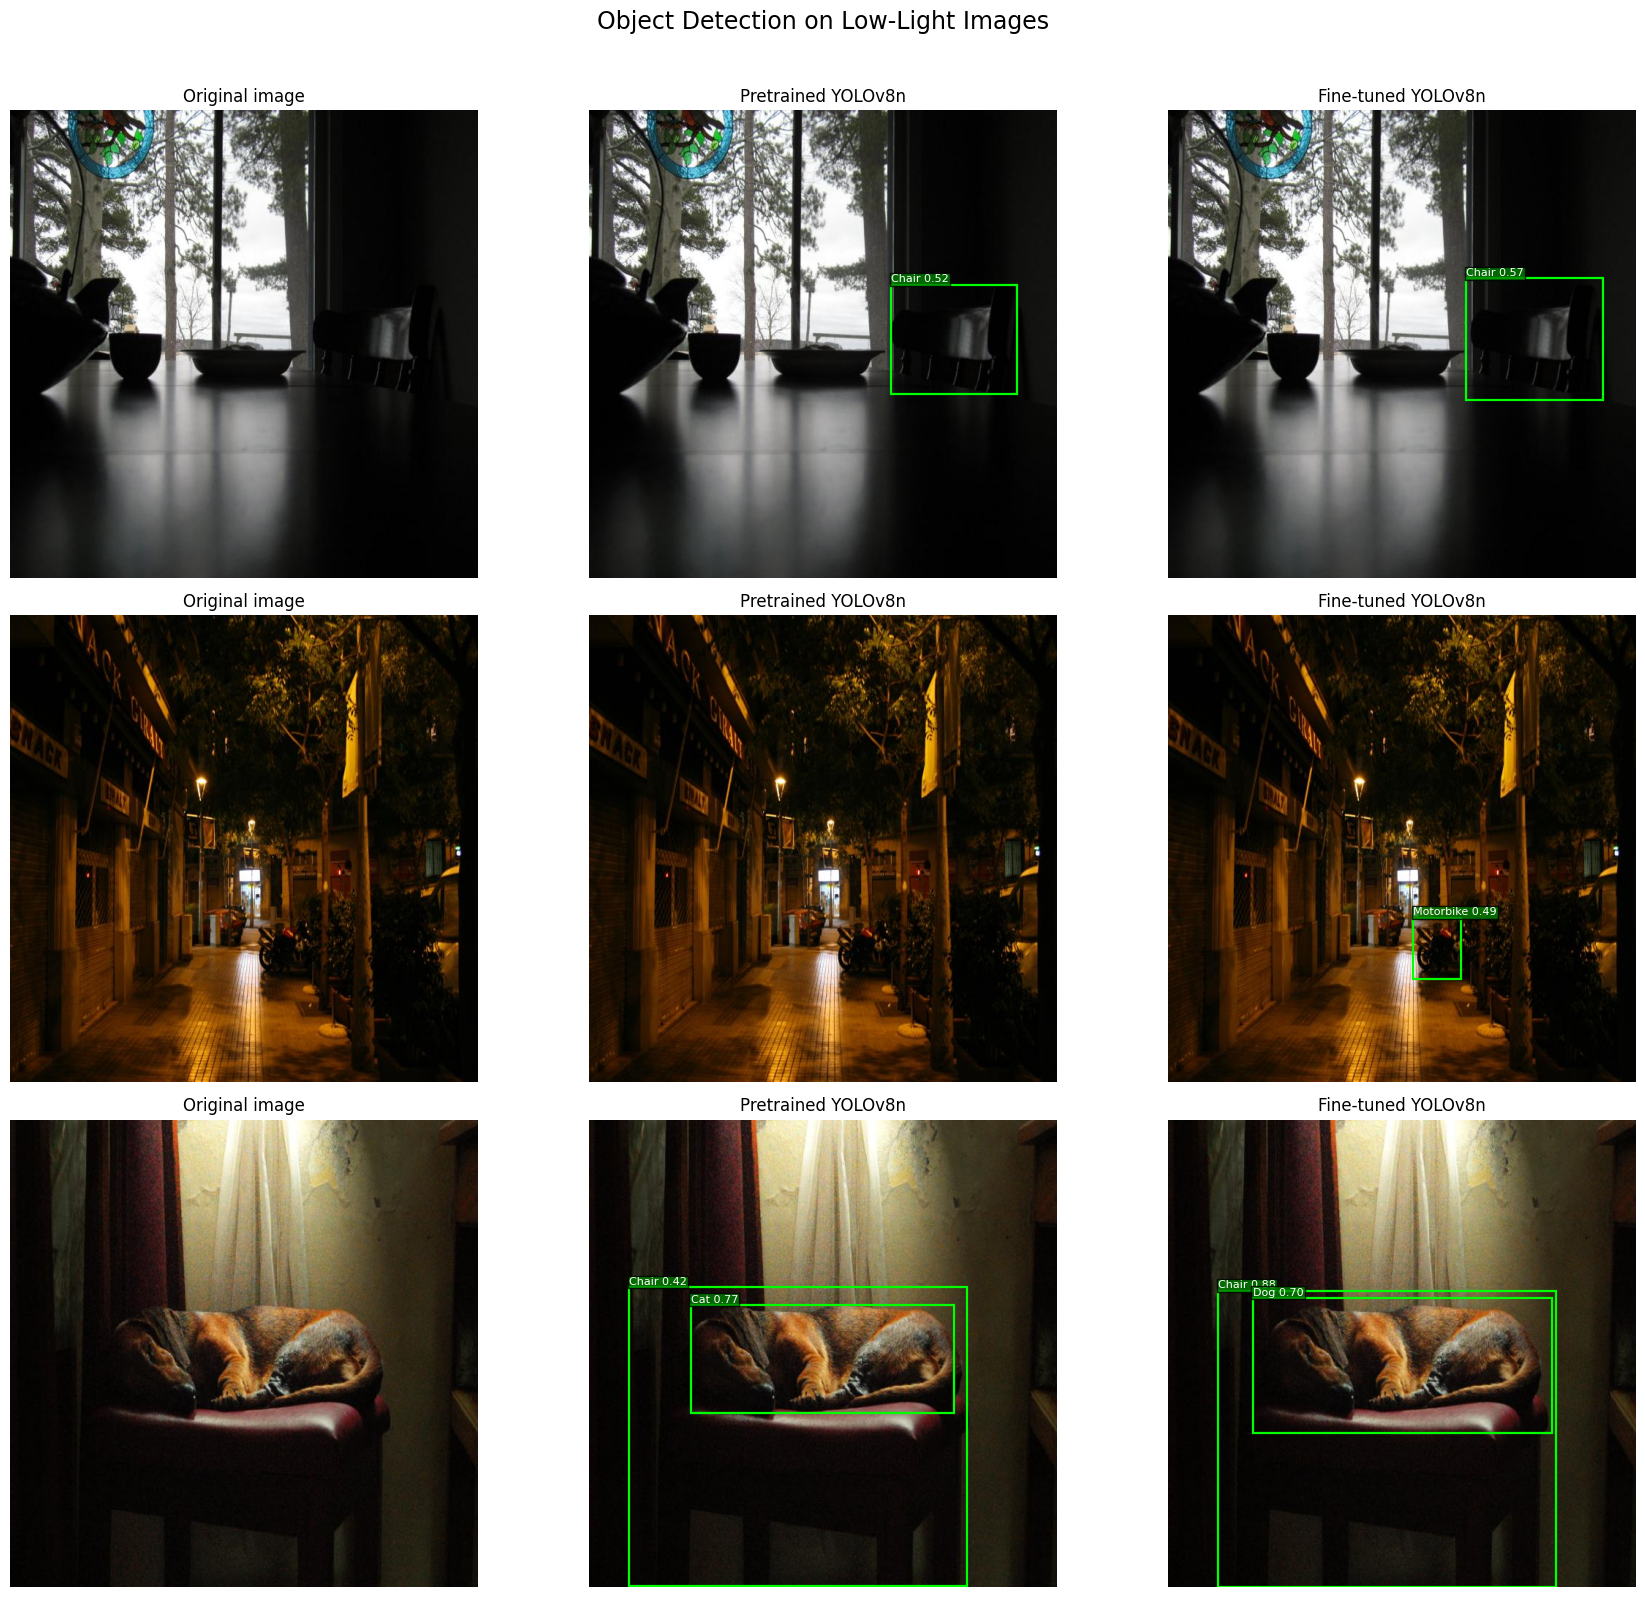

Saved: /content/report_figures/original_vs_pretrained_vs_finetuned.png


In [128]:
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

BASE = Path("/content")
OUTPUT_DIR = BASE / "report_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Bicycle", "Boat", "Bottle", "Bus", "Car", "Cat",
    "Chair", "Cup", "Dog", "Motorbike", "People", "Table"
]
CONF_THRESHOLD = 0.25

# Load existing prediction files. No inference or training required.
with open("/content/exdark_baseline/baseline_predictions.json") as f:
    baseline_preds = json.load(f)

with open("/content/exdark_finetune/fine_tuned_test_predictions.json") as f:
    finetuned_preds = json.load(f)

def index_predictions(data):
    return {
        Path(name).stem.lower(): detections
        for name, detections in data.items()
    }

baseline_index = index_predictions(baseline_preds)
finetuned_index = index_predictions(finetuned_preds)

def draw_detections(ax, image, detections, title):
    ax.imshow(image)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

    for det in detections:
        confidence = float(det.get("confidence", 0))
        if confidence < CONF_THRESHOLD:
            continue

        class_id = int(det["class_id"])
        x1, y1, x2, y2 = map(float, det["bbox"])

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=1.6,
            edgecolor="lime",
            facecolor="none",
        )
        ax.add_patch(rect)

        class_name = (
            CLASS_NAMES[class_id]
            if 0 <= class_id < len(CLASS_NAMES)
            else str(class_id)
        )
        ax.text(
            x1,
            max(0, y1 - 3),
            f"{class_name} {confidence:.2f}",
            color="white",
            fontsize=8,
            bbox=dict(facecolor="green", alpha=0.8, pad=1),
        )

fig, axes = plt.subplots(3, 3, figsize=(18, 16))

for row, stem in enumerate(selected_stems):
    original_path = image_indexes["Original"].get(stem)

    if original_path is None:
        print("Skipping missing image:", stem)
        continue

    with Image.open(original_path) as im:
        image = im.convert("RGB").copy()

    draw_detections(
        axes[row, 0], image, [],
        "Original image"
    )
    draw_detections(
        axes[row, 1], image,
        baseline_index.get(stem, []),
        "Pretrained YOLOv8n"
    )
    draw_detections(
        axes[row, 2], image,
        finetuned_index.get(stem, []),
        "Fine-tuned YOLOv8n"
    )

fig.suptitle(
    "Object Detection on Low-Light Images",
    fontsize=17,
    y=0.995,
)
fig.tight_layout(rect=[0, 0, 1, 0.98])

save_path = OUTPUT_DIR / "original_vs_pretrained_vs_finetuned.png"
fig.savefig(save_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", save_path)

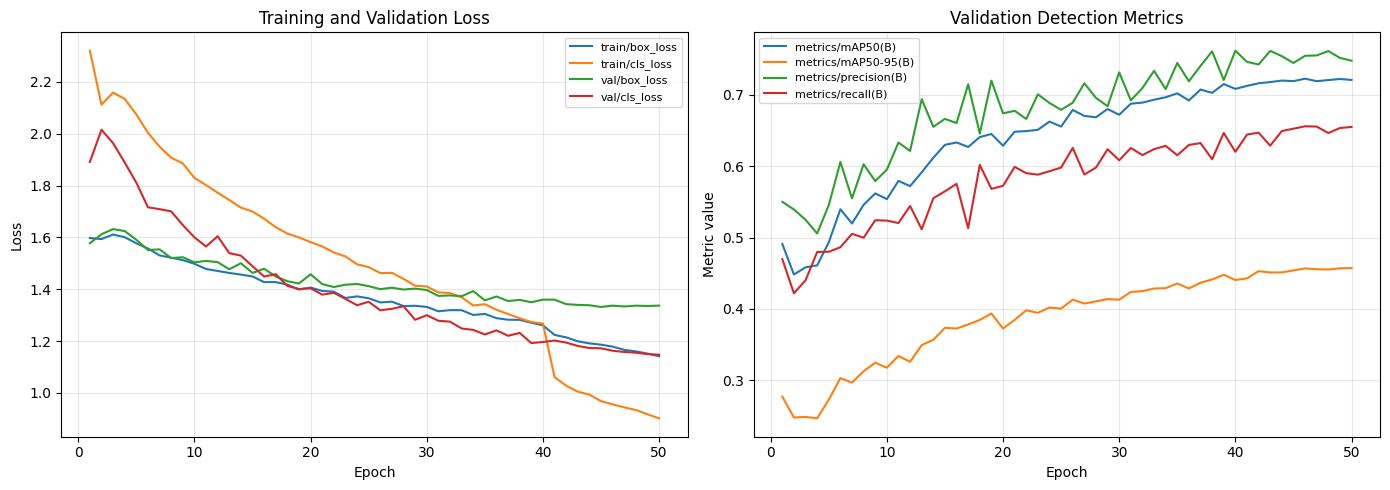

Saved: /content/report_figures/fine_tuning_training_curves.png


In [129]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

results_csv = Path(
    "/content/exdark_finetune/yolov8n_exdark_original/results.csv"
)
OUTPUT_DIR = Path("/content/report_figures")

if not results_csv.exists():
    print("Training results.csv was not found:", results_csv)
else:
    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()

    # Plot available validation metrics and training losses.
    preferred_columns = [
        "train/box_loss",
        "train/cls_loss",
        "val/box_loss",
        "val/cls_loss",
        "metrics/mAP50(B)",
        "metrics/mAP50-95(B)",
        "metrics/precision(B)",
        "metrics/recall(B)",
    ]

    available = [c for c in preferred_columns if c in df.columns]
    if "epoch" not in df.columns:
        df["epoch"] = range(1, len(df) + 1)

    if not available:
        print("No expected metric columns found.")
        print("Available columns:", df.columns.tolist())
    else:
        fig, axes = plt.subplots(
            1, 2, figsize=(14, 5)
        )

        loss_cols = [
            c for c in available
            if "loss" in c.lower()
        ]
        metric_cols = [
            c for c in available
            if "loss" not in c.lower()
        ]

        for col in loss_cols:
            axes[0].plot(df["epoch"], df[col], label=col)

        axes[0].set_title("Training and Validation Loss")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Loss")
        axes[0].grid(True, alpha=0.3)
        if loss_cols:
            axes[0].legend(fontsize=8)

        for col in metric_cols:
            axes[1].plot(df["epoch"], df[col], label=col)

        axes[1].set_title("Validation Detection Metrics")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Metric value")
        axes[1].grid(True, alpha=0.3)
        if metric_cols:
            axes[1].legend(fontsize=8)

        fig.tight_layout()
        curve_path = OUTPUT_DIR / "fine_tuning_training_curves.png"
        fig.savefig(curve_path, dpi=250, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        print("Saved:", curve_path)

In [130]:
import zipfile
from pathlib import Path
from google.colab import files

figure_dir = Path("/content/report_figures")
zip_path = "/content/report_figures.zip"

png_files = list(figure_dir.glob("*.png"))

if not png_files:
    raise FileNotFoundError(
        "No PNG figures found. Run the figure-generation cells first."
    )

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in png_files:
        zf.write(path, arcname=path.name)

print("Figures included:")
for path in png_files:
    print(" -", path.name)

files.download(zip_path)

Figures included:
 - original_vs_clahe.png
 - original_vs_pretrained_vs_finetuned.png
 - original_vs_sci.png
 - fine_tuning_training_curves.png
 - original_vs_gamma.png
 - original_vs_zero_dce.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [137]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

folders = {
    "Original": Path("/content/ExDark/data/test/images"),
    "Zero-DCE": Path("/content/exdark_phase2/zero_dce/images"),
    "SCI": Path("/content/exdark_phase2/sci/images"),
}

# Reuse the three images selected for your report.
# If selected_stems is no longer defined, select them again.
if "selected_stems" not in globals():
    import random

    def get_stems(folder):
        return {
            p.stem.lower()
            for p in folder.iterdir()
            if p.is_file()
            and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        }

    common = sorted(set.intersection(*(get_stems(p) for p in folders.values())))
    random.seed(42)
    selected_stems = random.sample(common, min(3, len(common)))

def image_path(folder, stem):
    matches = [
        p for p in folder.iterdir()
        if p.is_file() and p.stem.lower() == stem.lower()
        and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
    return matches[0] if matches else None

rows = []
fig, axes = plt.subplots(len(selected_stems), 3, figsize=(15, 5 * len(selected_stems)))
axes = np.array(axes).reshape(len(selected_stems), 3)

for i, stem in enumerate(selected_stems):
    for j, name in enumerate(folders):
        path = image_path(folders[name], stem)

        if path is None:
            axes[i, j].set_title(f"{name}: NOT FOUND")
            axes[i, j].axis("off")
            continue

        with Image.open(path) as im:
            img = im.convert("RGB").copy()

        arr = np.asarray(img, dtype=np.float32)
        gray = np.asarray(img.convert("L"), dtype=np.float32)

        rows.append({
            "Image": stem,
            "Method": name,
            "Resolution": f"{img.width}x{img.height}",
            "Mean brightness (0-255)": round(float(gray.mean()), 2),
            "Brightness std (contrast proxy)": round(float(gray.std()), 2),
            "Dark pixels (<20%)": round(float((gray < 51).mean() * 100), 2),
            "Bright pixels (>90%)": round(float((gray > 230).mean() * 100), 2),
        })

        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{name}\n{img.width}×{img.height}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

display(pd.DataFrame(rows))


Output hidden; open in https://colab.research.google.com to view.

In [136]:

from pathlib import Path
from PIL import Image
from torchvision.transforms.functional import to_tensor
from torchvision.utils import save_image
import torch
import time

SCI_OUTPUT_DIR = OUTPUT_ROOT / "sci" / "images"
SCI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = next(sci_model.parameters()).device
sci_model.eval()

start = time.time()

with torch.inference_mode():
    for idx, image_path in enumerate(test_images, start=1):
        image_path = Path(image_path)
        output_path = SCI_OUTPUT_DIR / f"{image_path.stem}.png"

        with Image.open(image_path) as im:
            input_tensor = to_tensor(
                im.convert("RGB")
            ).unsqueeze(0).to(device)

        # Official SCI returns (illumination map, reflectance).
        # The official test script saves the SECOND output.
        _, enhanced = sci_model(input_tensor)

        enhanced = enhanced.squeeze(0).clamp(0, 1).cpu()
        save_image(enhanced, str(output_path))

        if idx % 100 == 0 or idx == len(test_images):
            print(f"Processed {idx}/{len(test_images)} images")

print(f"Done: {len(test_images)} SCI images regenerated.")
print(f"Time: {time.time() - start:.1f} seconds")
print("Output:", SCI_OUTPUT_DIR)


Processed 100/734 images
Processed 200/734 images
Processed 300/734 images
Processed 400/734 images
Processed 500/734 images
Processed 600/734 images
Processed 700/734 images
Processed 734/734 images
Done: 734 SCI images regenerated.
Time: 87.0 seconds
Output: /content/exdark_phase2/sci/images
